# Positional Allograph Collapse
## Vocabulary reduction by positional homophony + neural decipherment

SilPart confirmed that 73% of glyphs are position-locked (syllabic notebook). The correct reading is **positional homophony**: N glyphs → 1 character, with selection by position (analogous to positional variants of Arabic).

**Hypothesis:** If we collapse glyphs that are positional variants of the same character (allographs), we reduce the vocabulary from ~166 to ~30-50 types, and neural decipherment with a single flat table improves root matching because consonantal patterns will be more coherent.

**Strategy:**
1. Feature vectors per glyph: transition profile + positional distribution
2. Hierarchical clustering: similar context + complementary positions + same C/V role
3. Corpus rewriting with cluster representatives
4. Standard neural decipherment on reduced vocabulary

In [1]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re, math, random, json, warnings, time, copy
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from scipy.spatial.distance import jensenshannon
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Additional imports for clustering
from sklearn.metrics.pairwise import cosine_similarity
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 130, 'savefig.dpi': 180,
    'font.size': 10, 'axes.titlesize': 11,
    'figure.facecolor': 'white',
})

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print('Imports OK')

Device: cuda
Imports OK


In [2]:
# ── Cell 2: Load Voynich corpus ─────────────────────────────────────
STA_PATH = 'corpus/voynich_sta.txt'

def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


# ── Segmentation and positional classification ──

def construir_matriz_transicion_intrapalabra(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


def segmentar_silabas_tp(palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20):
    all_trans_probs = []
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            if g1 in index_tr and g2 in index_tr:
                all_trans_probs.append(M_prob[index_tr[g1], index_tr[g2]])
    threshold_val = np.percentile(all_trans_probs, threshold_percentile)
    silabas_por_palabra = []
    for palabra in palabras:
        if len(palabra) == 0:
            continue
        syl = [palabra[0]]
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            p = M_prob[index_tr[g1], index_tr[g2]] if (g1 in index_tr and g2 in index_tr) else 0.0
            if p < threshold_val:
                silabas_por_palabra.append(tuple(syl))
                syl = [g2]
            else:
                syl.append(g2)
        if syl:
            silabas_por_palabra.append(tuple(syl))
        silabas_por_palabra.append(None)
    return silabas_por_palabra, all_trans_probs, threshold_val


def catalogar_silabas(silabas_por_palabra):
    syl_freq = Counter()
    syl_per_word = []
    syl_lengths = Counter()
    count_in_word = 0
    for item in silabas_por_palabra:
        if item is None:
            if count_in_word > 0:
                syl_per_word.append(count_in_word)
            count_in_word = 0
        else:
            syl_freq[item] += 1
            syl_lengths[len(item)] += 1
            count_in_word += 1
    if count_in_word > 0:
        syl_per_word.append(count_in_word)
    return syl_freq, syl_per_word, syl_lengths


def clasificar_silabas_posicionalmente(silabas_por_palabra, min_freq=5):
    words_as_syls = []
    current = []
    for item in silabas_por_palabra:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)
    pos_counts = defaultdict(lambda: {'inicio': 0, 'medio': 0, 'final': 0, 'total': 0})
    for word_syls in words_as_syls:
        n = len(word_syls)
        for i, syl in enumerate(word_syls):
            pos_counts[syl]['total'] += 1
            if n == 1:
                pos_counts[syl]['inicio'] += 1
                pos_counts[syl]['final'] += 1
            elif i == 0:
                pos_counts[syl]['inicio'] += 1
            elif i == n - 1:
                pos_counts[syl]['final'] += 1
            else:
                pos_counts[syl]['medio'] += 1
    clase_silaba = {}
    stats = {}
    for syl, counts in pos_counts.items():
        if counts['total'] < min_freq:
            continue
        total = counts['total']
        r_ini = counts['inicio'] / total
        r_fin = counts['final'] / total
        r_med = counts['medio'] / total
        if r_ini >= 0.60 and r_fin < 0.30:
            clase = 'onset'
        elif r_fin >= 0.60 and r_ini < 0.30:
            clase = 'coda'
        elif r_med >= 0.40:
            clase = 'nuclear'
        else:
            clase = 'free'
        clase_silaba[syl] = clase
        stats[syl] = {'clase': clase, 'inicio': r_ini, 'medio': r_med,
                       'final': r_fin, 'total': total}
    return clase_silaba, stats


def syls_to_words(syls_flat):
    words, current = [], []
    for item in syls_flat:
        if item is None:
            if current:
                words.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words.append(current)
    return words


def clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB):
    glyph_in_class = defaultdict(Counter)
    glyph_position = defaultdict(Counter)
    for word_syls in WORDS_SYL_V:
        for syl in word_syls:
            clase = clase_silaba_v.get(syl, 'free')
            for i, g in enumerate(syl):
                glyph_in_class[g][clase] += 1
                if i == 0:
                    glyph_position[g]['inicio'] += 1
                elif i == len(syl) - 1:
                    glyph_position[g]['fin'] += 1
                else:
                    glyph_position[g]['medio'] += 1
    glyph_role = {}
    glyph_stats = {}
    for g in VOCAB:
        counts = glyph_in_class[g]
        total = sum(counts.values())
        if total < 5:
            glyph_role[g] = '?'
            glyph_stats[g] = {'role': '?', 'total': total, 'pct_nuclear': 0}
            continue
        pct_nuclear = counts.get('nuclear', 0) / total
        pct_onset = counts.get('onset', 0) / total
        pct_coda = counts.get('coda', 0) / total
        glyph_role[g] = 'V' if pct_nuclear > 0.40 else 'C'
        glyph_stats[g] = {
            'role': glyph_role[g], 'total': total,
            'pct_nuclear': pct_nuclear, 'pct_onset': pct_onset,
            'pct_coda': pct_coda, 'pct_free': counts.get('free', 0) / total,
            'pos_inicio': glyph_position[g].get('inicio', 0),
            'pos_medio': glyph_position[g].get('medio', 0),
            'pos_fin': glyph_position[g].get('fin', 0),
        }
    return glyph_role, glyph_stats


# ── Load and process Voynich ──
tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))
N_VOYNICH = len(palabras)
glyph_freq = Counter(corpus_plano)

M_raw, M_prob, tokens_tr, index_tr = construir_matriz_transicion_intrapalabra(palabras)
SILABAS_VOYNICH, _, threshold_val = segmentar_silabas_tp(
    palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20)
syl_freq_v, syl_per_word_v, syl_lengths_v = catalogar_silabas(SILABAS_VOYNICH)
clase_silaba_v, stats_syl_v = clasificar_silabas_posicionalmente(SILABAS_VOYNICH, min_freq=5)
WORDS_SYL_V = syls_to_words(SILABAS_VOYNICH)
glyph_role, glyph_stats = clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB)

n_c = sum(1 for g in VOCAB if glyph_role[g] == 'C')
n_v = sum(1 for g in VOCAB if glyph_role[g] == 'V')
n_q = sum(1 for g in VOCAB if glyph_role[g] == '?')
print(f'Voynich: {N_VOYNICH:,} words, {len(corpus_plano):,} tokens, {len(VOCAB)} glyphs')
print(f'Classification: C={n_c}, V={n_v}, ?={n_q}')

Voynich: 37,087 words, 157,254 tokens, 166 glyphs
Classification: C=70, V=5, ?=91


In [3]:
# ── Cell 3: Load Hebrew corpus + CharLM baseline + grammar anchors ──

def descargar_hebreo():
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Downloading {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for capitulo in data['text']:
            for versiculo in capitulo:
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in pals:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    print(f'  Hebrew total: {len(todas_palabras):,} words')
    return todas_palabras

print('Downloading Hebrew corpus (Torah)...')
hebrew_words_full = descargar_hebreo()

# Subsample
rng_sub = np.random.default_rng(42)
if len(hebrew_words_full) > N_VOYNICH:
    idx = rng_sub.choice(len(hebrew_words_full), size=N_VOYNICH, replace=False)
    hebrew_words = [hebrew_words_full[i] for i in sorted(idx)]
else:
    hebrew_words = hebrew_words_full
print(f'Hebrew subsampled: {len(hebrew_words):,} words')

# Hebrew C/V classification
HEBREW_VOWELS = set('אהוי')  # matres lectionis
target_chars_heb = sorted(set(c for w in hebrew_words for c in w))
char_role_heb = {c: 'V' if c in HEBREW_VOWELS else 'C' for c in target_chars_heb}
n_c_h = sum(1 for c in target_chars_heb if char_role_heb[c] == 'C')
n_v_h = sum(1 for c in target_chars_heb if char_role_heb[c] == 'V')
print(f'Hebrew: {len(target_chars_heb)} chars (C={n_c_h}, V={n_v_h})')

# ── Trigram CharLM baseline (Witten-Bell) ──
class CharLM:
    def __init__(self, order=3):
        self.order = order
        self.trigram_counts = defaultdict(Counter)
        self.bigram_counts = defaultdict(Counter)
        self.unigram_counts = Counter()
        self.vocab = set()
        self.total = 0
        self._V = 0

    def fit(self, words):
        BOS, EOS = '<w>', '</w>'
        for word in words:
            seq = [BOS, BOS] + list(word) + [EOS]
            for c in seq:
                self.vocab.add(c)
                self.unigram_counts[c] += 1
                self.total += 1
            for i in range(len(seq) - 1):
                self.bigram_counts[seq[i]][seq[i+1]] += 1
            for i in range(len(seq) - 2):
                ctx = (seq[i], seq[i+1])
                self.trigram_counts[ctx][seq[i+2]] += 1
        self._V = len(self.vocab)

    def _log_prob_trigram(self, c1, c2, c3):
        ctx = (c1, c2)
        tri_counts = self.trigram_counts[ctx]
        tri_total = sum(tri_counts.values())
        if tri_total > 0:
            tri_seen = len(tri_counts)
            count = tri_counts.get(c3, 0)
            if count > 0:
                prob = count / (tri_total + tri_seen)
                return math.log2(max(prob, 1e-20))
            else:
                lambda_bo = tri_seen / (tri_total + tri_seen)
                bi_counts = self.bigram_counts[c2]
                bi_total = sum(bi_counts.values())
                if bi_total > 0:
                    bi_seen = len(bi_counts)
                    bi_count = bi_counts.get(c3, 0)
                    if bi_count > 0:
                        prob = lambda_bo * bi_count / (bi_total + bi_seen)
                    else:
                        lambda_bo2 = bi_seen / (bi_total + bi_seen)
                        prob = lambda_bo * lambda_bo2 * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                else:
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
        else:
            bi_counts = self.bigram_counts[c2]
            bi_total = sum(bi_counts.values())
            if bi_total > 0:
                bi_seen = len(bi_counts)
                count = bi_counts.get(c3, 0)
                if count > 0:
                    prob = count / (bi_total + bi_seen)
                else:
                    lambda_bo = bi_seen / (bi_total + bi_seen)
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
            else:
                prob = (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))

    def log_prob(self, word):
        BOS, EOS = '<w>', '</w>'
        seq = [BOS, BOS] + list(word) + [EOS]
        lp = 0.0
        for i in range(2, len(seq)):
            lp += self._log_prob_trigram(seq[i-2], seq[i-1], seq[i])
        return lp

    def perplexity(self, words):
        total_lp, total_n = 0.0, 0
        for word in words:
            total_lp += self.log_prob(word)
            total_n += len(word) + 1
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)

# Train baseline
char_lm_baseline = CharLM(order=3)
char_lm_baseline.fit(hebrew_words)
ppx_baseline = char_lm_baseline.perplexity(hebrew_words)
print(f'CharLM baseline native PPX: {ppx_baseline:.2f}')

# ── Grammar anchors ──
HEBREW_PREFIXES = set('והבכלמש')
HEBREW_SUFFIXES = set('התםןך')
HEBREW_ROOT_CONSONANTS = set('אבגדהוזחטיכלמנסעפצקרשת') - HEBREW_PREFIXES - HEBREW_SUFFIXES

GRAMMAR_ANCHORS = {
    'D1': HEBREW_PREFIXES,
    'K1': HEBREW_PREFIXES | {'ש'},
    'L1': {'ל', 'ה', 'ב', 'מ'},
    'Q1': HEBREW_ROOT_CONSONANTS,
    'Q2': HEBREW_ROOT_CONSONANTS,
    'A2': HEBREW_SUFFIXES,
    'C1': HEBREW_SUFFIXES,
}

def build_glyph_grammar_roles(palabras, glyph_stats, VOCAB):
    glyph_grammar_role = {}
    direct_rules = {
        'D1': 'prefix', 'K1': 'classifier', 'L1': 'prefix',
        'Q1': 'root', 'Q2': 'root',
        'A2': 'suffix', 'C1': 'suffix',
    }
    for g in VOCAB:
        if g in direct_rules:
            glyph_grammar_role[g] = direct_rules[g]
            continue
        s = glyph_stats.get(g, {})
        total = s.get('total', 0)
        if total < 10:
            continue
        pos_ini = s.get('pos_inicio', 0)
        pos_fin = s.get('pos_fin', 0)
        pos_med = s.get('pos_medio', 0)
        pos_total = pos_ini + pos_fin + pos_med
        if pos_total == 0:
            continue
        pct_onset = s.get('pct_onset', 0)
        pct_coda = s.get('pct_coda', 0)
        pct_nuclear = s.get('pct_nuclear', 0)
        r_ini = pos_ini / pos_total
        r_fin = pos_fin / pos_total
        if pct_onset > 0.50 and r_ini > 0.50:
            glyph_grammar_role[g] = 'prefix'
        elif pct_coda > 0.50 and r_fin > 0.50:
            glyph_grammar_role[g] = 'suffix'
        elif pct_nuclear > 0.40:
            glyph_grammar_role[g] = 'root'
    role_to_anchor = {
        'prefix': HEBREW_PREFIXES,
        'classifier': HEBREW_PREFIXES | {'ש'},
        'root': HEBREW_ROOT_CONSONANTS,
        'suffix': HEBREW_SUFFIXES,
    }
    glyph_anchor_sets = {}
    for g, role in glyph_grammar_role.items():
        glyph_anchor_sets[g] = role_to_anchor.get(role, set())
    return glyph_grammar_role, glyph_anchor_sets

glyph_grammar_role, glyph_anchor_sets = build_glyph_grammar_roles(
    palabras, glyph_stats, VOCAB)

role_counts = Counter(glyph_grammar_role.values())
print(f'\nGrammar anchors: {len(glyph_grammar_role)} glyphs')
for role, cnt in sorted(role_counts.items(), key=lambda x: -x[1]):
    print(f'  {role}: {cnt}')

  Hebrew total: 80,051 words
Hebrew subsampled: 37,087 words
Hebrew: 27 chars (C=23, V=4)
CharLM baseline native PPX: 7.32

Grammar anchors: 12 glyphs
  root: 7
  suffix: 2
  prefix: 2
  classifier: 1


In [4]:
# ── Cell 4: NeuralCharLM — LSTM architecture ─────────────────────────

class CharDataset(Dataset):
    def __init__(self, words, char2idx):
        self.samples = []
        bos = char2idx['<w>']
        eos = char2idx['</w>']
        for word in words:
            indices = [bos, bos] + [char2idx.get(c, char2idx.get('<unk>', 0)) for c in word] + [eos]
            for i in range(2, len(indices)):
                ctx = indices[i-2:i]
                target = indices[i]
                self.samples.append((ctx, target))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ctx, target = self.samples[idx]
        return torch.tensor(ctx, dtype=torch.long), torch.tensor(target, dtype=torch.long)


class NeuralCharLM(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=192, n_layers=2, dropout=0.2):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                           dropout=dropout if n_layers > 1 else 0.0,
                           batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.char2idx = None
        self.idx2char = None

    def forward(self, x, hidden=None):
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden

    def log_prob(self, word, temperature=1.0):
        self.eval()
        with torch.no_grad():
            bos = self.char2idx['<w>']
            eos = self.char2idx['</w>']
            unk = self.char2idx.get('<unk>', 0)
            indices = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
            total_lp = 0.0
            for i in range(2, len(indices)):
                ctx = torch.tensor([[indices[i-2], indices[i-1]]], device=DEVICE)
                logits, _ = self.forward(ctx)
                logits_t = logits[0, -1, :] / temperature
                log_probs = torch.log_softmax(logits_t, dim=0)
                total_lp += log_probs[indices[i]].item() / math.log(2)
            return total_lp

    def batch_log_prob(self, words, temperature=1.0):
        self.eval()
        bos = self.char2idx['<w>']
        eos = self.char2idx['</w>']
        unk = self.char2idx.get('<unk>', 0)
        with torch.no_grad():
            all_ctx = []
            all_tgt = []
            word_boundaries = [0]
            for word in words:
                seq = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
                for i in range(2, len(seq)):
                    all_ctx.append([seq[i-2], seq[i-1]])
                    all_tgt.append(seq[i])
                word_boundaries.append(len(all_ctx))
            n_total = len(all_ctx)
            if n_total == 0:
                return np.zeros(len(words))
            ctx_t = torch.tensor(all_ctx, device=DEVICE)
            tgt_t = torch.tensor(all_tgt, device=DEVICE)
            CHUNK = 16384
            all_lps = []
            for start in range(0, n_total, CHUNK):
                end = min(start + CHUNK, n_total)
                logits, _ = self.forward(ctx_t[start:end])
                logits_last = logits[:, -1, :] / temperature
                log_p = torch.log_softmax(logits_last, dim=-1)
                target_lp = log_p.gather(1, tgt_t[start:end].unsqueeze(1)).squeeze(1)
                all_lps.append(target_lp)
            all_lps = torch.cat(all_lps).cpu().numpy() / math.log(2)
            word_lps = np.zeros(len(words))
            for wi in range(len(words)):
                start = word_boundaries[wi]
                end = word_boundaries[wi + 1]
                if start < end:
                    word_lps[wi] = all_lps[start:end].sum()
            return word_lps

    def perplexity(self, words, temperature=1.0):
        self.eval()
        word_lps = self.batch_log_prob(words, temperature)
        total_lp = word_lps.sum()
        total_n = sum(len(w) + 1 for w in words)
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)


# ── Build vocabulary and indices ──
all_chars_heb = sorted(set(c for w in hebrew_words for c in w))
special_tokens = ['<pad>', '<w>', '</w>', '<unk>']
char_vocab = special_tokens + all_chars_heb
char2idx = {c: i for i, c in enumerate(char_vocab)}
idx2char = {i: c for c, i in char2idx.items()}

print(f'Neural LM vocab: {len(char_vocab)} tokens ({len(all_chars_heb)} chars + {len(special_tokens)} special)')
n_params = sum(p.numel() for p in NeuralCharLM(len(char_vocab)).parameters())
print(f'Parameters: {n_params:,}')

Neural LM vocab: 31 tokens (27 chars + 4 special)
Parameters: 476,991


Train: 29,670 words, Val: 7,417 words
Train samples: 142,813, Val samples: 35,563

Training Neural LM (30 epochs, patience=5)...
  Epoch  1: train_loss=2.3489, val_loss=2.1332, lr=0.001995
  Epoch  5: train_loss=2.0585, val_loss=2.0321, lr=0.001866
  Epoch 10: train_loss=2.0338, val_loss=2.0166, lr=0.001500
  Epoch 15: train_loss=2.0196, val_loss=2.0105, lr=0.001000
  Epoch 20: train_loss=2.0101, val_loss=2.0060, lr=0.000500
  Epoch 25: train_loss=2.0050, val_loss=2.0046, lr=0.000134
  Epoch 30: train_loss=2.0005, val_loss=2.0041, lr=0.000000

Entrenamiento completado en 47.9s

Perplexity en validación (2000 words):
  CharLM trigram (baseline): 7.37
  NeuralCharLM (T=1.0):     7.48


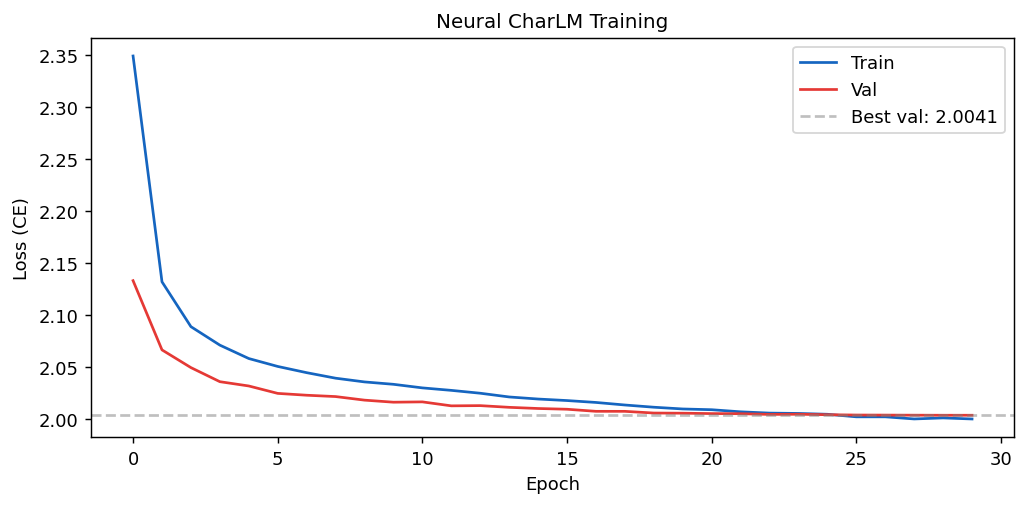

In [5]:
# ── Cell 5: Neural LM training ──────────────────────────────

rng_split = np.random.default_rng(42)
n_val = int(0.2 * len(hebrew_words))
perm = rng_split.permutation(len(hebrew_words))
val_idx = set(perm[:n_val])
train_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i not in val_idx]
val_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i in val_idx]
print(f'Train: {len(train_words):,} words, Val: {len(val_words):,} words')

train_dataset = CharDataset(train_words, char2idx)
val_dataset = CharDataset(val_words, char2idx)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=0)
print(f'Train samples: {len(train_dataset):,}, Val samples: {len(val_dataset):,}')

neural_lm = NeuralCharLM(len(char_vocab), embed_dim=32, hidden_dim=192,
                          n_layers=2, dropout=0.2).to(DEVICE)
neural_lm.char2idx = char2idx
neural_lm.idx2char = idx2char

optimizer = optim.AdamW(neural_lm.parameters(), lr=2e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
criterion = nn.CrossEntropyLoss(ignore_index=char2idx['<pad>'])

N_EPOCHS = 30
PATIENCE = 5
best_val_loss = float('inf')
patience_counter = 0
train_losses = []
val_losses = []

print(f'\nTraining Neural LM ({N_EPOCHS} epochs, patience={PATIENCE})...')
t0 = time.time()

for epoch in range(N_EPOCHS):
    neural_lm.train()
    epoch_loss = 0.0
    n_batches = 0
    for ctx_batch, target_batch in train_loader:
        ctx_batch = ctx_batch.to(DEVICE)
        target_batch = target_batch.to(DEVICE)
        optimizer.zero_grad()
        logits, _ = neural_lm(ctx_batch)
        loss = criterion(logits[:, -1, :], target_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(neural_lm.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    train_loss = epoch_loss / max(n_batches, 1)
    train_losses.append(train_loss)

    neural_lm.eval()
    val_loss = 0.0
    n_val_batches = 0
    with torch.no_grad():
        for ctx_batch, target_batch in val_loader:
            ctx_batch = ctx_batch.to(DEVICE)
            target_batch = target_batch.to(DEVICE)
            logits, _ = neural_lm(ctx_batch)
            loss = criterion(logits[:, -1, :], target_batch)
            val_loss += loss.item()
            n_val_batches += 1
    val_loss = val_loss / max(n_val_batches, 1)
    val_losses.append(val_loss)
    scheduler.step()

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f'  Epoch {epoch+1:2d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, '
              f'lr={scheduler.get_last_lr()[0]:.6f}')

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0
        best_state_dict = copy.deepcopy(neural_lm.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'  Early stopping at epoch {epoch+1}')
            break

elapsed = time.time() - t0
print(f'\nTraining completed in {elapsed:.1f}s')

neural_lm.load_state_dict(best_state_dict)

neural_val_ppx = neural_lm.perplexity(val_words[:2000], temperature=1.0)
baseline_val_ppx = char_lm_baseline.perplexity(val_words[:2000])
print(f'\nPerplexity on validation (2000 words):')
print(f'  CharLM trigram (baseline): {baseline_val_ppx:.2f}')
print(f'  NeuralCharLM (T=1.0):     {neural_val_ppx:.2f}')

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.plot(train_losses, label='Train', color='#1565C0')
ax.plot(val_losses, label='Val', color='#E53935')
ax.axhline(best_val_loss, linestyle='--', color='gray', alpha=0.5, label=f'Best val: {best_val_loss:.4f}')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (CE)')
ax.set_title('Neural CharLM Training')
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
# ── Cell 6: Positional allograph clustering ─────────────────────────────

# ══════════════════════════════════════════════════════════════════════
# Part A: Feature vectors per glyph
# ══════════════════════════════════════════════════════════════════════

MIN_GLYPH_FREQ = 10  # only glyphs with freq >= 10

def compute_intra_syllable_positions(words_syl):
    """For each glyph, count occurrences as onset/nucleus/coda."""
    pos_counts = defaultdict(lambda: Counter())
    for word_syls in words_syl:
        for syl in word_syls:
            n = len(syl)
            if n == 1:
                pos_counts[syl[0]]['nucleus'] += 1
            elif n == 2:
                pos_counts[syl[0]]['onset'] += 1
                pos_counts[syl[1]]['coda'] += 1
            else:
                pos_counts[syl[0]]['onset'] += 1
                pos_counts[syl[-1]]['coda'] += 1
                for g in syl[1:-1]:
                    pos_counts[g]['nucleus'] += 1
    return pos_counts

def positional_distribution_word(glyph, palabras):
    """Positional distribution within word: [initial, middle, final]."""
    counts = np.array([0.0, 0.0, 0.0])
    for word in palabras:
        for i, g in enumerate(word):
            if g == glyph:
                if len(word) == 1:
                    counts[0] += 0.5; counts[2] += 0.5
                elif i == 0:
                    counts[0] += 1
                elif i == len(word) - 1:
                    counts[2] += 1
                else:
                    counts[1] += 1
    total = counts.sum()
    return counts / total if total > 0 else np.array([1/3, 1/3, 1/3])

# Intra-syllable positions
intra_pos = compute_intra_syllable_positions(WORDS_SYL_V)

# Filter frequent glyphs
freq_glyphs = [g for g in VOCAB if glyph_freq[g] >= MIN_GLYPH_FREQ]
print(f'Glyphs with freq >= {MIN_GLYPH_FREQ}: {len(freq_glyphs)} / {len(VOCAB)}')

# Feature vectors
glyph_to_idx = {g: i for i, g in enumerate(tokens_tr)}
N_GL = len(tokens_tr)

# Transition profiles: row (what follows) + column (what precedes) from M_prob
transition_profiles = {}
for g in freq_glyphs:
    if g in glyph_to_idx:
        idx = glyph_to_idx[g]
        row = M_prob[idx, :]   # what follows
        col = M_prob[:, idx]   # what precedes
        transition_profiles[g] = np.concatenate([row, col])
    else:
        transition_profiles[g] = np.zeros(2 * N_GL)

# Intra-syllable distribution (3D: onset%, nucleus%, coda%)
intra_syl_dist = {}
for g in freq_glyphs:
    counts = intra_pos.get(g, Counter())
    total = sum(counts.values())
    if total > 0:
        intra_syl_dist[g] = np.array([
            counts.get('onset', 0) / total,
            counts.get('nucleus', 0) / total,
            counts.get('coda', 0) / total,
        ])
    else:
        intra_syl_dist[g] = np.array([1/3, 1/3, 1/3])

# Word-level positional distribution (3D: initial%, middle%, final%)
word_pos_dist = {}
for g in freq_glyphs:
    word_pos_dist[g] = positional_distribution_word(g, palabras)

print(f'Feature vectors built for {len(freq_glyphs)} glyphs')

# ══════════════════════════════════════════════════════════════════════
# Part B: Contextual similarity matrix
# ══════════════════════════════════════════════════════════════════════

# Cosine similarity on transition profiles
trans_matrix = np.array([transition_profiles[g] for g in freq_glyphs])
sim_context = cosine_similarity(trans_matrix)

# JSD on intra-syllable positional distributions
n_fg = len(freq_glyphs)
dist_position = np.zeros((n_fg, n_fg))
for i in range(n_fg):
    for j in range(i+1, n_fg):
        d = jensenshannon(intra_syl_dist[freq_glyphs[i]] + 1e-10,
                          intra_syl_dist[freq_glyphs[j]] + 1e-10)
        dist_position[i, j] = d
        dist_position[j, i] = d

print(f'sim_context shape: {sim_context.shape}')
print(f'dist_position shape: {dist_position.shape}')

# ══════════════════════════════════════════════════════════════════════
# Part C: Identify candidate allograph pairs
# ══════════════════════════════════════════════════════════════════════

def dominant_position(dist_3d):
    """Return the dominant position: 0=onset, 1=nucleus, 2=coda."""
    return int(np.argmax(dist_3d))

def positions_complementary(g1, g2, intra_syl_dist):
    """Two glyphs are complementary if they dominate different positions."""
    d1 = dominant_position(intra_syl_dist[g1])
    d2 = dominant_position(intra_syl_dist[g2])
    return d1 != d2

SIM_THRESHOLD = 0.6
n_candidates = 0
candidate_pairs = []

for i in range(n_fg):
    for j in range(i+1, n_fg):
        g1, g2 = freq_glyphs[i], freq_glyphs[j]
        # Criterion 1: high contextual similarity
        if sim_context[i, j] < SIM_THRESHOLD:
            continue
        # Criterion 2: same C/V role
        r1 = glyph_role.get(g1, '?')
        r2 = glyph_role.get(g2, '?')
        if r1 != r2 and r1 != '?' and r2 != '?':
            continue
        # Criterion 3: complementary positions
        complementary = positions_complementary(g1, g2, intra_syl_dist)
        candidate_pairs.append({
            'g1': g1, 'g2': g2,
            'sim': sim_context[i, j],
            'complementary': complementary,
            'role1': r1, 'role2': r2,
            'dom1': ['onset', 'nucleus', 'coda'][dominant_position(intra_syl_dist[g1])],
            'dom2': ['onset', 'nucleus', 'coda'][dominant_position(intra_syl_dist[g2])],
        })

print(f'\nCandidate pairs (sim > {SIM_THRESHOLD}, same role): {len(candidate_pairs)}')
n_comp = sum(1 for p in candidate_pairs if p['complementary'])
print(f'  Of which, complementary: {n_comp}')

# Top-10 pairs by similarity
candidate_pairs.sort(key=lambda p: p['sim'], reverse=True)
print('\nTop-10 candidate pairs:')
df_pairs = pd.DataFrame(candidate_pairs[:10])
if len(df_pairs) > 0:
    print(df_pairs[['g1', 'g2', 'sim', 'complementary', 'role1', 'dom1', 'dom2']].to_string(index=False))

# ══════════════════════════════════════════════════════════════════════
# Part D: Hierarchical clustering + threshold sweep
# ══════════════════════════════════════════════════════════════════════

# Distance = 1 - sim_context (clipped to [0, 1])
dist_matrix = np.clip(1.0 - sim_context, 0, 1)
np.fill_diagonal(dist_matrix, 0)

# Condensed distance matrix
condensed = squareform(dist_matrix)
Z = linkage(condensed, method='average')
print(f'\nLinkage completed: {Z.shape[0]} merges')

# Threshold sweep
thresholds = np.arange(0.10, 0.80, 0.02)
sweep_results = []
for t in thresholds:
    labels = fcluster(Z, t=t, criterion='distance')
    n_clusters = len(set(labels))
    sweep_results.append({'threshold': t, 'n_clusters': n_clusters})

df_sweep = pd.DataFrame(sweep_results)
print('\nThreshold sweep (sample):')
for _, row in df_sweep.iloc[::5].iterrows():
    print(f'  t={row["threshold"]:.2f} → {int(row["n_clusters"])} clusters')

# Select optimal threshold: the smallest that yields 30-50 clusters
# If none found, take the closest to 40
target_range = (30, 50)
in_range = df_sweep[(df_sweep['n_clusters'] >= target_range[0]) &
                     (df_sweep['n_clusters'] <= target_range[1])]

if len(in_range) > 0:
    # Prefer highest threshold within the range (more conservative)
    optimal_row = in_range.iloc[-1]
else:
    # Closest to 40
    df_sweep['dist_to_40'] = abs(df_sweep['n_clusters'] - 40)
    optimal_row = df_sweep.loc[df_sweep['dist_to_40'].idxmin()]

OPTIMAL_THRESHOLD = float(optimal_row['threshold'])
labels_opt = fcluster(Z, t=OPTIMAL_THRESHOLD, criterion='distance')
N_REDUCED_RAW = len(set(labels_opt))
print(f'\nOptimal threshold: {OPTIMAL_THRESHOLD:.2f} → {N_REDUCED_RAW} clusters')

# ══════════════════════════════════════════════════════════════════════
# Part E: Post-filter + Corpus rewriting
# ══════════════════════════════════════════════════════════════════════

# Build clusters
cluster_members = defaultdict(list)
for i, lab in enumerate(labels_opt):
    cluster_members[lab].append(freq_glyphs[i])

# Post-filter: only merge clusters where at least one pair is complementary
# or where all members have the same role
final_clusters = {}
split_count = 0
for lab, members in cluster_members.items():
    if len(members) == 1:
        final_clusters[members[0]] = members
        continue
    # Check: all same role?
    roles = set(glyph_role.get(g, '?') for g in members)
    roles.discard('?')
    if len(roles) > 1:
        # Mixed roles → split
        for g in members:
            final_clusters[g] = [g]
        split_count += 1
        continue
    final_clusters[f'cluster_{lab}'] = members

print(f'Post-filter clusters: {len(final_clusters)} (split {split_count} due to mixed roles)')

# Map glyph → representative (most frequent in cluster)
cluster_map = {}
cluster_info = {}
for key, members in final_clusters.items():
    representative = max(members, key=lambda g: glyph_freq[g])
    for g in members:
        cluster_map[g] = representative
    if len(members) > 1:
        cluster_info[representative] = {
            'members': members,
            'freqs': {g: glyph_freq[g] for g in members},
            'roles': [glyph_role.get(g, '?') for g in members],
            'positions': [['onset', 'nucleus', 'coda'][dominant_position(intra_syl_dist[g])]
                         for g in members],
        }

# Infrequent glyphs: each one is its own cluster
for g in VOCAB:
    if g not in cluster_map:
        cluster_map[g] = g

# Rewrite corpus
def rewrite_word(word, cmap):
    return [cmap.get(g, g) for g in word]

palabras_reduced = [rewrite_word(w, cluster_map) for w in palabras]
corpus_plano_reduced = [g for p in palabras_reduced for g in p]
VOCAB_REDUCED = sorted(set(corpus_plano_reduced))
glyph_freq_reduced = Counter(corpus_plano_reduced)

# Update roles for reduced vocabulary
glyph_role_reduced = {}
for g in VOCAB_REDUCED:
    glyph_role_reduced[g] = glyph_role.get(g, '?')

print(f'\n{"="*50}')
print(f'VOCABULARY REDUCTION')
print(f'{"="*50}')
print(f'Original: {len(VOCAB)} glyphs')
print(f'Reduced: {len(VOCAB_REDUCED)} glyphs')
print(f'Reduction: {len(VOCAB) - len(VOCAB_REDUCED)} glyphs ({100*(len(VOCAB)-len(VOCAB_REDUCED))/len(VOCAB):.1f}%)')
print(f'Clusters with ≥2 members: {len(cluster_info)}')
print(f'Unique words original: {len(set(tuple(w) for w in words))}')
print(f'Unique words reduced: {len(set(tuple(w) for w in words_reduced))}')

Glyphs with freq >= 10: 57 / 166
Feature vectors built for 57 glyphs
sim_context shape: (57, 57)
dist_position shape: (57, 57)

Candidate pairs (sim > 0.6, same role): 200
  Of which, complementary: 65

Top-10 candidate pairs:
g1 g2      sim  complementary role1    dom1  dom2
D1 Da 0.999844          False     C   onset onset
V2 W2 0.993328          False     C   onset onset
V2 W1 0.989428          False     C   onset onset
W1 W2 0.985504          False     C   onset onset
U4 V2 0.984289          False     C   onset onset
F3 X1 0.979748           True     C nucleus onset
U3 U4 0.978425          False     C   onset onset
U4 W1 0.975034          False     C   onset onset
T2 U2 0.974514          False     C   onset onset
U4 W2 0.972393          False     C   onset onset

Linkage completed: 56 merges

Threshold sweep (sample):
  t=0.10 → 42 clusters
  t=0.20 → 35 clusters
  t=0.30 → 30 clusters
  t=0.40 → 27 clusters
  t=0.50 → 26 clusters
  t=0.60 → 24 clusters
  t=0.70 → 21 clusters

Opti

Clusters with >=2 members:
 Representative Size Role Members                                 Positions                    
----------------------------------------------------------------------------------------------------
            D1    2    C D1, Da                                   onset, onset                  
            F1    7    C B4, Cd, F1, F3, G3, H1, X1               nucleus, onset, coda, nucleus, nucleus, nucleus, onset
            Ba    2    C B5, Ba                                   onset, onset                  
            U2   14    C E2, M1, N1, T1, T2, Tb, U2, U3, U4, U5, V1, V2, W1, W2 nucleus, onset, onset, onset, onset, onset, onset, onset, onset, onset, onset, onset, onset, onset


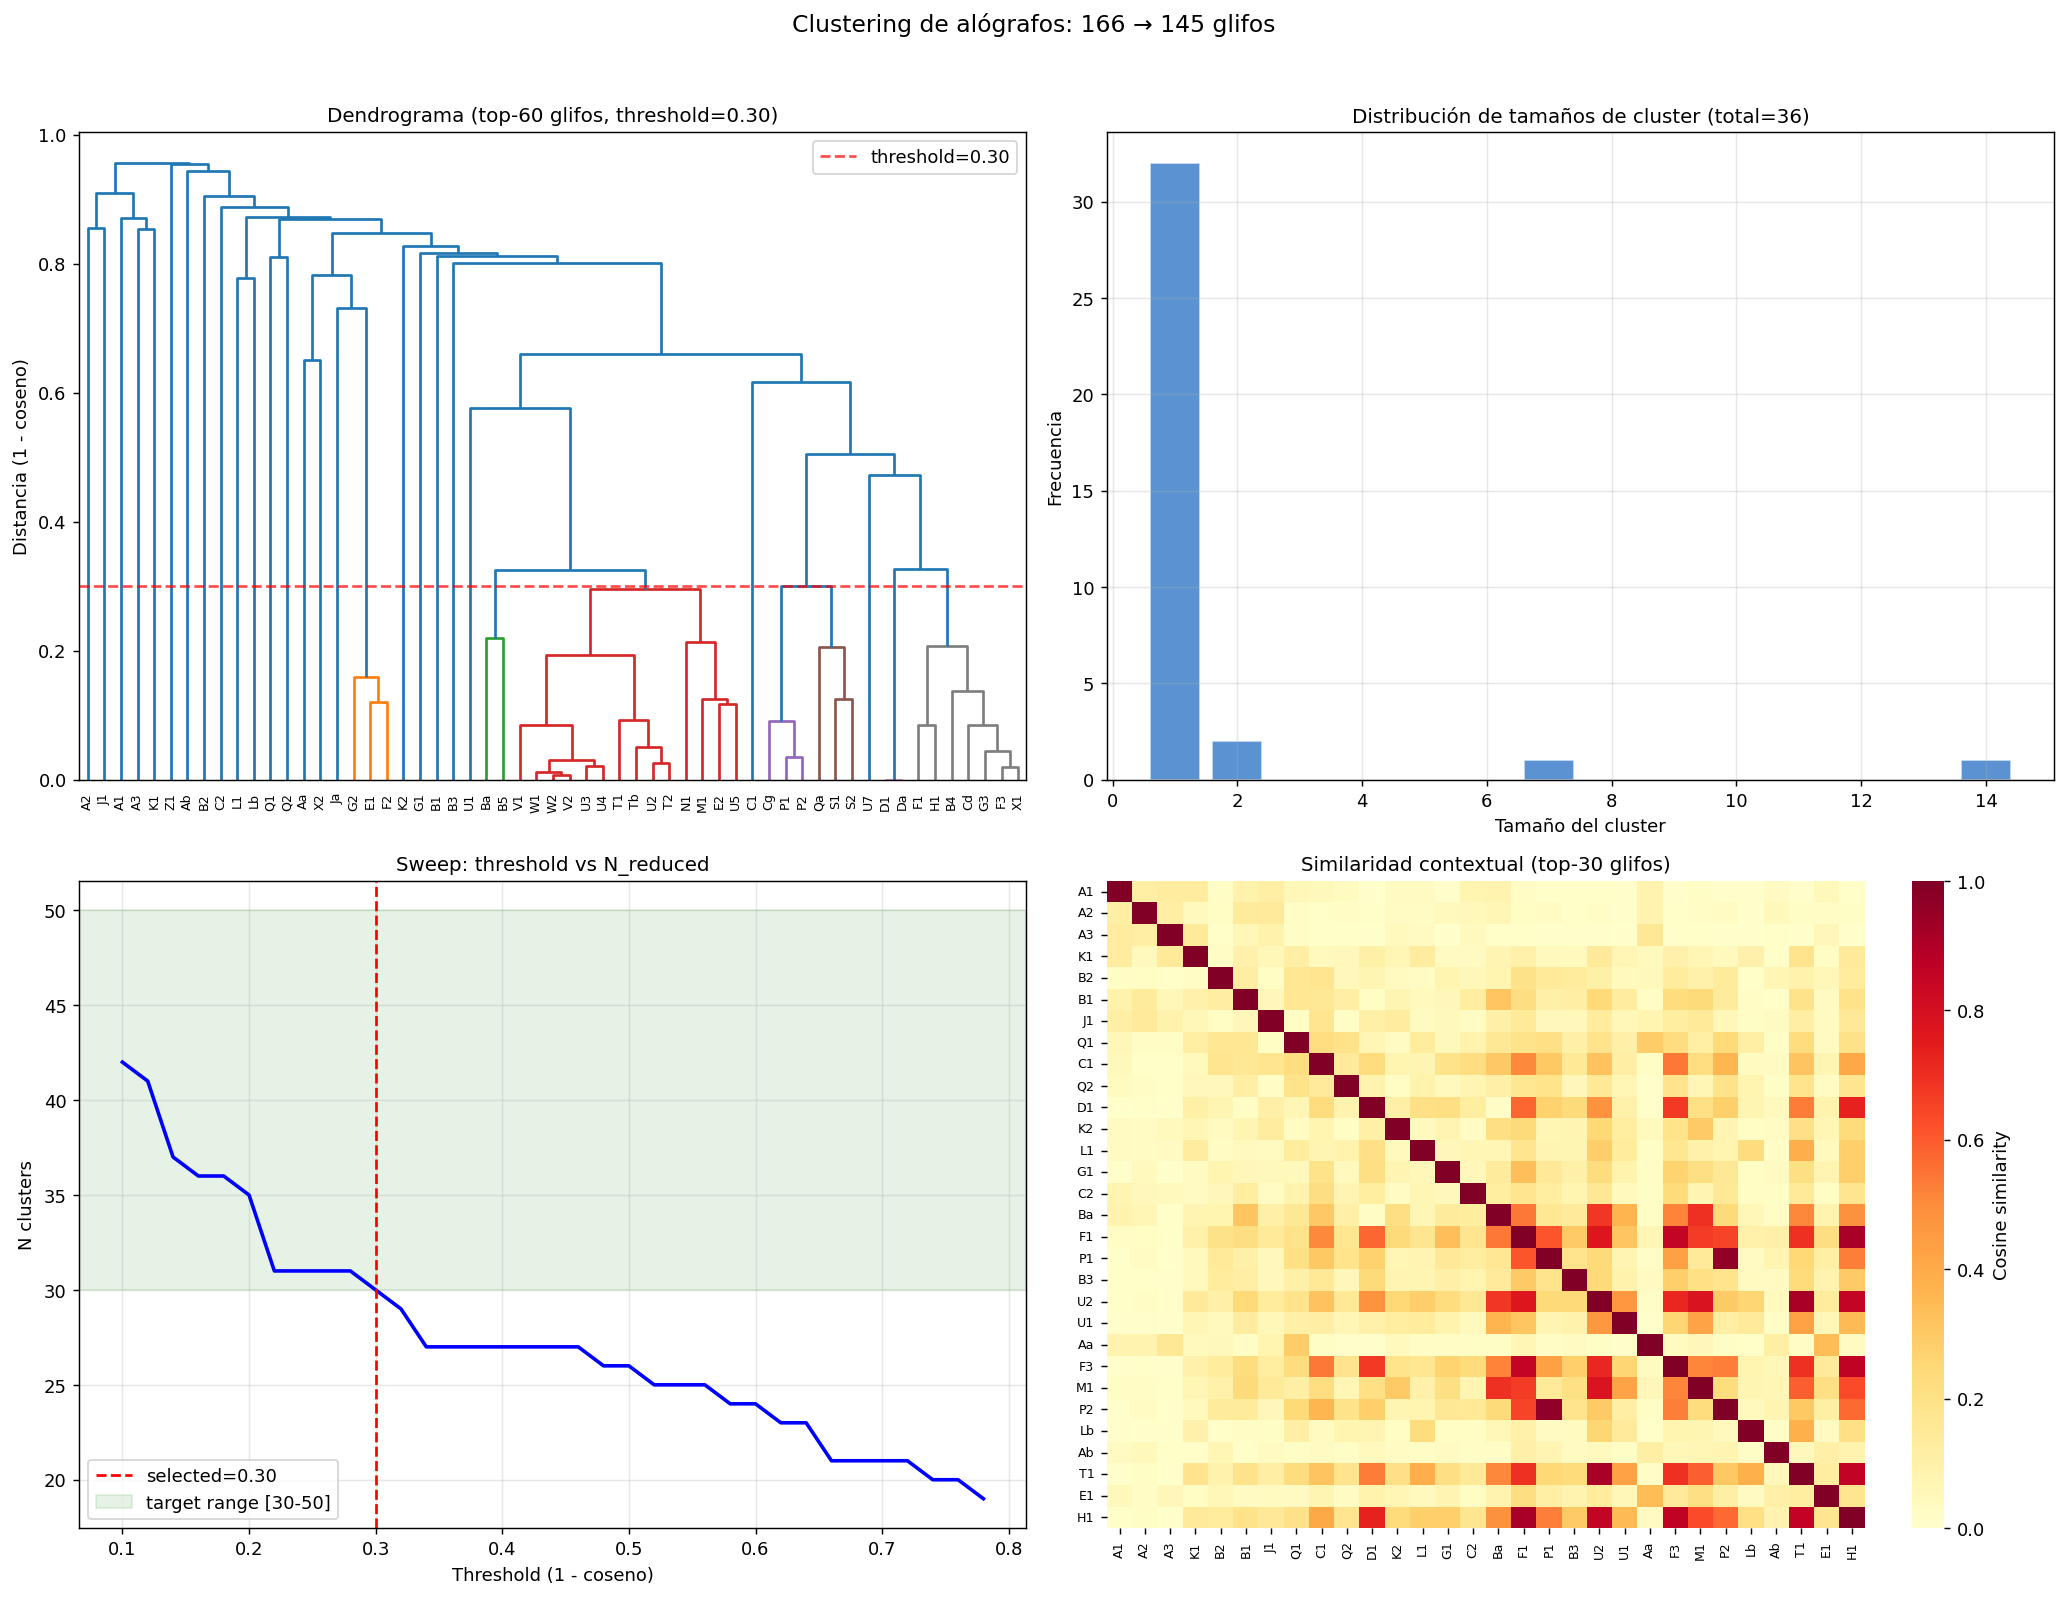

In [7]:
# ── Cell 7: Clustering analysis ─────────────────────────────────────

# Table: clusters with ≥2 glyphs
print('Clusters with ≥2 members:')
print(f'{"Representative":>14} {"Size":>4} {"Role":>4} {"Members":<40} {"Positions":<30}')
print('-' * 100)
for rep, info in sorted(cluster_info.items(), key=lambda x: -sum(x[1]['freqs'].values())):
    members_str = ', '.join(info['members'])
    pos_str = ', '.join(info['positions'])
    role = info['roles'][0] if info['roles'] else '?'
    print(f'{rep:>14} {len(info["members"]):>4} {role:>4} {members_str:<40} {pos_str:<30}')

# ── Dendrogram of top-60 glyphs ──
top60_freq = sorted(freq_glyphs, key=lambda g: glyph_freq[g], reverse=True)[:60]
top60_idx = [freq_glyphs.index(g) for g in top60_freq if g in freq_glyphs]
top60_labels = [freq_glyphs[i] for i in top60_idx]

# Sub-distance matrix
dist_sub = dist_matrix[np.ix_(top60_idx, top60_idx)]
condensed_sub = squareform(dist_sub)
Z_sub = linkage(condensed_sub, method='average')

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Dendrogram
ax = axes[0, 0]
dendrogram(Z_sub, labels=top60_labels, ax=ax, leaf_rotation=90, leaf_font_size=7,
           color_threshold=OPTIMAL_THRESHOLD)
ax.axhline(OPTIMAL_THRESHOLD, color='red', linestyle='--', alpha=0.7,
           label=f'threshold={OPTIMAL_THRESHOLD:.2f}')
ax.set_title(f'Dendrogram (top-60 glyphs, threshold={OPTIMAL_THRESHOLD:.2f})')
ax.set_ylabel('Distance (1 - cosine)')
ax.legend()

# Plot 2: Cluster size distribution
ax = axes[0, 1]
sizes = [len(members) for members in final_clusters.values()]
size_counts = Counter(sizes)
ax.bar(size_counts.keys(), size_counts.values(), color='#1565C0', alpha=0.7, edgecolor='white')
ax.set_xlabel('Cluster size')
ax.set_ylabel('Frequency')
ax.set_title(f'Cluster size distribution (total={len(final_clusters)})')
ax.grid(True, alpha=0.3)

# Plot 3: Sweep plot
ax = axes[1, 0]
ax.plot([r['threshold'] for r in sweep_results],
        [r['n_clusters'] for r in sweep_results],
        'b-', linewidth=2)
ax.axvline(OPTIMAL_THRESHOLD, color='red', linestyle='--', label=f'selected={OPTIMAL_THRESHOLD:.2f}')
ax.axhspan(30, 50, alpha=0.1, color='green', label='target range [30-50]')
ax.set_xlabel('Threshold (1 - cosine)')
ax.set_ylabel('N clusters')
ax.set_title('Sweep: threshold vs N_reduced')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: sim_context heatmap (top-30)
ax = axes[1, 1]
top30_idx = [freq_glyphs.index(g) for g in top60_freq[:30] if g in freq_glyphs]
top30_labels = [freq_glyphs[i] for i in top30_idx]
sim_sub = sim_context[np.ix_(top30_idx, top30_idx)]
sns.heatmap(sim_sub, ax=ax, xticklabels=top30_labels, yticklabels=top30_labels,
            cmap='YlOrRd', vmin=0, vmax=1, cbar_kws={'label': 'Cosine similarity'})
ax.set_title('Contextual similarity (top-30 glyphs)')
ax.tick_params(labelsize=7)

plt.suptitle(f'Allograph clustering: {len(VOCAB)} → {len(VOCAB_REDUCED)} glyphs', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [8]:
# ── Cell 8: GlyphMappingState + Scoring + Root helpers (for reduced vocab) ──

class GlyphMappingState:
    def __init__(self, voynich_glyphs, target_chars, glyph_role=None, char_role=None):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.glyph_role = glyph_role or {}
        self.char_role = char_role or {}
        self.mapping = {}

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def propose_change(self, rng, constrained=True):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        new.mapping[glyph] = rng.choice(candidates)
        return new

    def propose_change_tracked(self, rng, constrained=True):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        new.mapping[glyph] = rng.choice(candidates)
        return new, glyph

    def apply_word(self, word_glyphs):
        return [self.mapping.get(g, '?') for g in word_glyphs]

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]


def init_frequency_mapping(palabras, vocab_glyphs, target_chars, target_words,
                           glyph_role, char_role):
    gf = Counter(g for p in palabras for g in p)
    cf = Counter(c for w in target_words for c in w)
    mapping = {}
    for role in ('C', 'V', '?'):
        glyphs_r = sorted([g for g in vocab_glyphs if glyph_role.get(g, '?') == role],
                          key=lambda g: gf[g], reverse=True)
        if role == '?':
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        else:
            chars_r = sorted([c for c in target_chars if char_role.get(c) == role],
                             key=lambda c: cf.get(c, 0), reverse=True)
        if not chars_r:
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        for i, g in enumerate(glyphs_r):
            mapping[g] = chars_r[i % len(chars_r)]
    return mapping


def build_glyph_word_index(words):
    idx = defaultdict(list)
    for wi, word in enumerate(words):
        for g in set(word):
            idx[g].append(wi)
    return idx


# ── Scoring functions ──

def score_positional(mapping, glyph_role, char_role):
    n_ok = sum(1 for g, c in mapping.mapping.items()
               if glyph_role.get(g, '?') == char_role.get(c, '?')
               and glyph_role.get(g) != '?')
    n_total = sum(1 for g in mapping.mapping if glyph_role.get(g) != '?')
    return n_ok / max(n_total, 1)


def score_grammar(mapping_state, glyph_anchor_sets):
    if not glyph_anchor_sets:
        return 0.0
    n_anchored, score = 0, 0.0
    for g, anchor_set in glyph_anchor_sets.items():
        if not anchor_set:
            continue
        n_anchored += 1
        if mapping_state.mapping.get(g) in anchor_set:
            score += 1.0
        else:
            score -= 1.0
    return score / max(n_anchored, 1)


def score_entropy(mapping_state):
    char_counts = Counter(mapping_state.mapping.values())
    if len(char_counts) <= 1:
        return 0.0
    total = sum(char_counts.values())
    probs = np.array([c / total for c in char_counts.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    H_max = np.log2(len(char_counts))
    return H / H_max if H_max > 1e-10 else 0.0


def score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature=1.0):
    mapped = [mapping_state.apply_word(w) for w in words_sample]
    word_lps = neural_lm.batch_log_prob(mapped, temperature)
    return float(np.mean(word_lps)), word_lps


def score_cardinality(mapping_state, K_max=23):
    K = len(set(mapping_state.mapping.values()))
    if K >= K_max:
        return 0.0
    return -((K_max - K) ** 2)


def score_total_neural(mapping_state, words_sample, neural_lm, temperature,
                       glyph_role, char_role, glyph_anchor_sets,
                       w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3,
                       w_gram=1.0, K_max=23):
    s_lm, word_lps = score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature)
    s_pos = score_positional(mapping_state, glyph_role, char_role)
    s_card = score_cardinality(mapping_state, K_max)
    s_ent = score_entropy(mapping_state)
    s_gram = score_grammar(mapping_state, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, word_lps


def score_total_incremental(proposal, changed_glyph, words_sample, neural_lm,
                            temperature, glyph_role, char_role, glyph_anchor_sets,
                            glyph_word_idx, prev_word_lps,
                            w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3,
                            w_gram=1.0, K_max=23):
    new_word_lps = prev_word_lps.copy()
    affected = glyph_word_idx.get(changed_glyph, [])
    if affected:
        affected_mapped = [proposal.apply_word(words_sample[wi]) for wi in affected]
        new_lps = neural_lm.batch_log_prob(affected_mapped, temperature)
        for j, wi in enumerate(affected):
            new_word_lps[wi] = new_lps[j]
    s_lm = float(np.mean(new_word_lps))
    s_pos = score_positional(proposal, glyph_role, char_role)
    s_card = score_cardinality(proposal, K_max)
    s_ent = score_entropy(proposal)
    s_gram = score_grammar(proposal, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, new_word_lps


# ── Root helpers ──
HEBREW_CONSONANTS_SET = set('בגדהוזחטיכלמנסעפצקרשת') | set('ךםןףץ')
HEBREW_MATRES = set('אוי')
HEBREW_ROOTS = {
    'אמר', 'דבר', 'היה', 'בוא', 'עשה', 'נתן', 'ידע', 'הלך', 'ראה', 'שמע',
    'אכל', 'לקח', 'ישב', 'קרא', 'שלח', 'עלה', 'מות', 'שוב', 'ברך', 'יצא',
    'עבר', 'שמר', 'כתב', 'נשא', 'זכר', 'ילד', 'עמד', 'פנה', 'בנה', 'נפל',
    'שים', 'חיה', 'גדל', 'קום', 'מלא', 'מצא', 'שפט', 'אהב', 'ירד', 'נגד',
    'יסף', 'חטא', 'קדש', 'כהן', 'צוה', 'ברא', 'גלה', 'זבח', 'טהר', 'טמא',
    'ארץ', 'בית', 'שנה', 'יום', 'מים', 'שמש', 'ליל', 'אבן', 'עיר', 'דרך',
    'מלך', 'כסף', 'זהב', 'דמם', 'רוח', 'נפש', 'לחם', 'עין', 'ידד', 'שדה',
    'עבד', 'כלי', 'פרי', 'חדש', 'ספר', 'עצם', 'בשר', 'אדם', 'נהר', 'גבר',
    'רגל', 'ראש', 'חזק', 'רבב', 'קטן', 'טוב', 'רעע', 'חכם', 'צדק', 'רחם',
    'כול', 'בקר', 'צאן', 'עוף', 'דגג', 'שמן', 'יין', 'סוס', 'גמל', 'חמר',
}

def extract_skeleton(mapped_word, confidences, conf_threshold, glyph_word):
    skeleton = []
    for i, char in enumerate(mapped_word):
        if char in HEBREW_MATRES:
            continue
        if char not in HEBREW_CONSONANTS_SET:
            continue
        if i < len(glyph_word):
            g = glyph_word[i]
            if confidences.get(g, 0) < conf_threshold:
                skeleton.append('*')
            else:
                skeleton.append(char)
        else:
            skeleton.append(char)
    return ''.join(skeleton)

def match_skeleton_to_root(skeleton, root):
    if len(skeleton) != len(root):
        return False
    return all(s == '*' or s == r for s, r in zip(skeleton, root))

def extract_skeleton_deterministic(mapped_word):
    skeleton = []
    for char in mapped_word:
        if char in HEBREW_MATRES:
            continue
        if char in HEBREW_CONSONANTS_SET:
            skeleton.append(char)
    return ''.join(skeleton)

def count_roots_quick(mapping, palabras_sample, top_n=200):
    word_freq = Counter(tuple(w) for w in palabras_sample)
    top_words = word_freq.most_common(top_n)
    roots_matched = set()
    n_matches = 0
    for word_tuple, freq in top_words:
        mapped = [mapping.get(g, '?') for g in word_tuple]
        skel = extract_skeleton_deterministic(mapped)
        if len(skel) < 3:
            continue
        for i in range(len(skel) - 2):
            trigram = skel[i:i+3]
            if trigram in HEBREW_ROOTS:
                roots_matched.add(trigram)
                n_matches += 1
    return roots_matched, n_matches


# ── Adapt grammar anchors for reduced vocabulary ──
# Grammar anchors are defined on original glyphs. Remap to representative.
glyph_anchor_sets_reduced = {}
for g_orig, anchor_set in glyph_anchor_sets.items():
    g_rep = cluster_map.get(g_orig, g_orig)
    if g_rep in VOCAB_REDUCED:
        if g_rep not in glyph_anchor_sets_reduced:
            glyph_anchor_sets_reduced[g_rep] = set()
        glyph_anchor_sets_reduced[g_rep] |= anchor_set

print(f'Scoring + Root helpers loaded')
print(f'VOCAB_REDUCED: {len(VOCAB_REDUCED)} glyphs')
print(f'Grammar anchors (reduced): {len(glyph_anchor_sets_reduced)} glyphs')
print(f'Hebrew roots: {len(HEBREW_ROOTS)}')

Scoring + Root helpers loaded
VOCAB_REDUCED: 145 glyphs
Grammar anchors (reduced): 12 glyphs
Hebrew roots: 100


In [9]:
# ── Cell 9: Multi-Seed EM on reduced vocabulary ──────────────────────

N_SEEDS = 10
T_VALUES = [2.0, 3.0]
SCORE_KW = dict(w_gram=2.0, w_card=0.5, K_max=20)
SAMPLE_EM = 3000
EM_ITERS = 2000
EM_PATIENCE = 100
PROPOSALS_PER_ITER = 200

# Prepare EM sample (on reduced corpus)
rng_sample = np.random.default_rng(42)
if len(palabras_reduced) > SAMPLE_EM:
    idx_em = rng_sample.choice(len(palabras_reduced), size=SAMPLE_EM, replace=False)
    words_em = [palabras_reduced[i] for i in idx_em]
else:
    words_em = palabras_reduced

glyph_word_idx_em = build_glyph_word_index(words_em)

# Base frequency mapping (on reduced vocab)
base_mapping = init_frequency_mapping(
    palabras_reduced, VOCAB_REDUCED, target_chars_heb, hebrew_words,
    glyph_role_reduced, char_role_heb)

em_results = []

print(f'Multi-Seed EM: {N_SEEDS} seeds × {len(T_VALUES)} T = {N_SEEDS * len(T_VALUES)} runs')
print(f'Reduced vocabulary: {len(VOCAB_REDUCED)} glyphs')
print(f'Sample: {len(words_em)} words, {EM_ITERS} iter, patience={EM_PATIENCE}')
print()

for T in T_VALUES:
    for seed_idx in range(N_SEEDS):
        rng = np.random.default_rng(42 + seed_idx * 137 + int(T * 1000))

        state = GlyphMappingState(VOCAB_REDUCED, target_chars_heb,
                                  glyph_role_reduced, char_role_heb)
        if seed_idx < 5:
            mapping_init = dict(base_mapping)
            glyphs_to_scramble = rng.choice(VOCAB_REDUCED,
                                            size=max(1, len(VOCAB_REDUCED) // 3), replace=False)
            for g in glyphs_to_scramble:
                role = glyph_role_reduced.get(g, '?')
                if role in ('C', 'V'):
                    candidates = [c for c in target_chars_heb if char_role_heb.get(c) == role]
                else:
                    candidates = target_chars_heb
                mapping_init[g] = rng.choice(candidates)
            state.set_mapping(mapping_init)
        else:
            mapping_init = {}
            for g in VOCAB_REDUCED:
                role = glyph_role_reduced.get(g, '?')
                if role in ('C', 'V'):
                    candidates = [c for c in target_chars_heb if char_role_heb.get(c) == role]
                else:
                    candidates = target_chars_heb
                mapping_init[g] = rng.choice(candidates)
            state.set_mapping(mapping_init)

        best_score, best_word_lps = score_total_neural(
            state, words_em, neural_lm, T,
            glyph_role_reduced, char_role_heb, glyph_anchor_sets_reduced, **SCORE_KW)
        best_state = state
        no_improve = 0

        t0 = time.time()
        for it in range(EM_ITERS):
            improved = False
            for _ in range(PROPOSALS_PER_ITER):
                proposal, changed_glyph = best_state.propose_change_tracked(rng, constrained=True)
                prop_score, prop_word_lps = score_total_incremental(
                    proposal, changed_glyph, words_em, neural_lm, T,
                    glyph_role_reduced, char_role_heb, glyph_anchor_sets_reduced,
                    glyph_word_idx_em, best_word_lps, **SCORE_KW)
                if prop_score > best_score:
                    best_state = proposal
                    best_score = prop_score
                    best_word_lps = prop_word_lps
                    improved = True

            if not improved:
                no_improve += 1
                if no_improve >= EM_PATIENCE:
                    break
            else:
                no_improve = 0

        elapsed = time.time() - t0
        K_eff = len(set(best_state.mapping.values()))
        gram = score_grammar(best_state, glyph_anchor_sets_reduced)
        roots_found, n_matches = count_roots_quick(best_state.mapping, palabras_reduced)

        result = {
            'seed': seed_idx, 'T': T, 'score': best_score, 'K_eff': K_eff,
            'grammar': gram, 'n_roots': len(roots_found), 'roots': roots_found,
            'n_matches': n_matches, 'elapsed': elapsed,
            'state': best_state, 'word_lps': best_word_lps,
            'iter_converged': it + 1,
        }
        em_results.append(result)

        init_type = 'freq+scramble' if seed_idx < 5 else 'random_CV'
        print(f'  T={T:.1f} Seed {seed_idx:2d} [{init_type:13s}]: score={best_score:.4f}, K={K_eff:2d}, '
              f'gram={gram:.2f}, roots={len(roots_found):2d}, iter={it+1}, {elapsed:.0f}s')
    print()

# Summary
print(f'{"="*60}')
print('Summary Multi-Seed EM')
print(f'{"="*60}')
df_em = pd.DataFrame([{
    'T': r['T'], 'Seed': r['seed'],
    'Init': 'freq' if r['seed'] < 5 else 'rand',
    'Score': f"{r['score']:.4f}", 'K_eff': r['K_eff'],
    'Grammar': f"{r['grammar']:.2f}", 'Roots': r['n_roots'],
    'Iter': r['iter_converged'], 'Time': f"{r['elapsed']:.0f}s"
} for r in em_results])
print(df_em.to_string(index=False))

scores_all = [r['score'] for r in em_results]
roots_all = [r['n_roots'] for r in em_results]
print(f'\nScore: mean={np.mean(scores_all):.4f}, std={np.std(scores_all):.4f}')
print(f'Roots: mean={np.mean(roots_all):.1f}, std={np.std(roots_all):.1f}, '
      f'min={min(roots_all)}, max={max(roots_all)}')

Multi-Seed EM: 10 seeds × 2 T = 20 runs
Reduced vocabulary: 145 glyphs
Sample: 3000 words, 2000 iter, patience=100

  T=2.0 Seed  0 [freq+scramble]: score=-36.4768, K=27, gram=0.67, roots= 2, iter=264, 102s
  T=2.0 Seed  1 [freq+scramble]: score=-36.6658, K=27, gram=1.00, roots= 1, iter=294, 118s
  T=2.0 Seed  2 [freq+scramble]: score=-36.2751, K=27, gram=1.00, roots= 3, iter=241, 98s
  T=2.0 Seed  3 [freq+scramble]: score=-36.8315, K=27, gram=1.00, roots= 2, iter=299, 120s
  T=2.0 Seed  4 [freq+scramble]: score=-36.2209, K=27, gram=0.83, roots= 3, iter=244, 97s
  T=2.0 Seed  5 [random_CV    ]: score=-37.3441, K=26, gram=1.00, roots= 2, iter=180, 71s
  T=2.0 Seed  6 [random_CV    ]: score=-37.9805, K=27, gram=1.00, roots= 3, iter=213, 85s
  T=2.0 Seed  7 [random_CV    ]: score=-35.9738, K=27, gram=1.00, roots= 1, iter=240, 94s
  T=2.0 Seed  8 [random_CV    ]: score=-36.1419, K=26, gram=1.00, roots= 0, iter=496, 197s
  T=2.0 Seed  9 [random_CV    ]: score=-36.7111, K=27, gram=0.83, root

In [10]:
# ── Cell 10: Best candidate selection ───────────────────────────────

print(f'Total runs: {len(em_results)}')

# Filter: K_eff >= 20, grammar >= 0.8, score in top-50%
scores_all = [r['score'] for r in em_results]
score_median = np.median(scores_all)

candidates = [r for r in em_results
              if r['K_eff'] >= 20
              and r['grammar'] >= 0.8
              and r['score'] >= score_median]

print(f'Filtered candidates (K>=20, gram>=0.8, score>=median): {len(candidates)}')

if not candidates:
    print('No candidates meet all criteria. Relaxing: K>=15, gram>=0.5')
    candidates = [r for r in em_results
                  if r['K_eff'] >= 15
                  and r['grammar'] >= 0.5
                  and r['score'] >= score_median]
    print(f'Relaxed candidates: {len(candidates)}')

if not candidates:
    print('Still no candidates. Using all runs.')
    candidates = em_results

# Sort by roots (primary), then score (secondary)
candidates.sort(key=lambda r: (r['n_roots'], r['score']), reverse=True)

# Show top-5
print(f'\nTop-5 candidates:')
df_top = pd.DataFrame([{
    'T': r['T'], 'Seed': r['seed'],
    'Score': f"{r['score']:.4f}",
    'K_eff': r['K_eff'], 'Grammar': f"{r['grammar']:.2f}",
    'Roots': r['n_roots'],
} for r in candidates[:5]])
print(df_top.to_string(index=False))

BEST = candidates[0]
print(f'\nSelected: T={BEST["T"]}, seed={BEST["seed"]}, '
      f'roots={BEST["n_roots"]}, score={BEST["score"]:.4f}')

Total runs: 20
Filtered candidates (K>=20, gram>=0.8, score>=median): 10

Top-5 candidates:
  T  Seed    Score  K_eff Grammar  Roots
3.0     0 -36.4339     27    1.00      4
3.0     4 -36.1334     27    1.00      3
2.0     4 -36.2209     27    0.83      3
2.0     2 -36.2751     27    1.00      3
2.0     7 -35.9738     27    1.00      1

Selected: T=3.0, seed=0, roots=4, score=-36.4339


In [11]:
# ── Cell 11: MCMC multi-chain ─────────────────────────────────────────

T_mcmc = BEST['T']
print(f'MCMC with: T={T_mcmc}')

MCMC_SAMPLE = 3000
rng_mcmc = np.random.default_rng(42)
if len(palabras_reduced) > MCMC_SAMPLE:
    idx_mc = rng_mcmc.choice(len(palabras_reduced), size=MCMC_SAMPLE, replace=False)
    words_mcmc = [palabras_reduced[i] for i in idx_mc]
else:
    words_mcmc = palabras_reduced

glyph_word_idx_mcmc = build_glyph_word_index(words_mcmc)

N_CHAINS = 4
N_ITER = 20000
BURN_IN = 5000
THIN = 10
SEEDS_MCMC = [42, 137, 256, 999]

# Adaptive temperature calibration
def calibrate_mcmc_temp(state, words_sample, neural_lm, T_lm, glyph_role, char_role,
                        glyph_anchor_sets, glyph_word_idx, n_cal=300,
                        target_accept=0.35, **score_kwargs):
    rng_cal = np.random.default_rng(0)
    neg_deltas = []
    cal_state = state
    cal_score, cal_word_lps = score_total_neural(
        state, words_sample, neural_lm, T_lm,
        glyph_role, char_role, glyph_anchor_sets, **score_kwargs)
    for _ in range(n_cal):
        prop, changed = cal_state.propose_change_tracked(rng_cal, constrained=True)
        ps, pw = score_total_incremental(
            prop, changed, words_sample, neural_lm, T_lm,
            glyph_role, char_role, glyph_anchor_sets,
            glyph_word_idx, cal_word_lps, **score_kwargs)
        d = ps - cal_score
        if d < 0:
            neg_deltas.append(abs(d))
        cal_state = prop
        cal_score = ps
        cal_word_lps = pw
    if neg_deltas:
        median_neg = float(np.median(neg_deltas))
        T_start = median_neg / (-math.log(target_accept))
        T_end = T_start / 100
        return T_start, T_end
    return 1.0, 0.01

T_anneal_start, T_anneal_end = calibrate_mcmc_temp(
    BEST['state'], words_mcmc, neural_lm, T_mcmc,
    glyph_role_reduced, char_role_heb, glyph_anchor_sets_reduced,
    glyph_word_idx_mcmc, **SCORE_KW)
print(f'Calibrated T_anneal: {T_anneal_start:.6f} -> {T_anneal_end:.8f}')

# Run chains
mcmc_chains = []
global_best = None
global_best_score = -np.inf

for chain_idx in range(N_CHAINS):
    seed = SEEDS_MCMC[chain_idx]
    print(f'\n  Chain {chain_idx+1}/{N_CHAINS} (seed={seed})')
    rng_ch = np.random.default_rng(seed)

    current = GlyphMappingState(VOCAB_REDUCED, target_chars_heb,
                                glyph_role_reduced, char_role_heb)
    current.set_mapping(dict(BEST['state'].mapping))
    current_score, current_word_lps = score_total_neural(
        current, words_mcmc, neural_lm, T_mcmc,
        glyph_role_reduced, char_role_heb, glyph_anchor_sets_reduced, **SCORE_KW)

    best_ch = current
    best_ch_score = current_score
    chain_scores = [current_score]
    chain_mappings = [dict(current.mapping)]
    accepted = 0
    _thin = 0

    t0 = time.time()
    for it in range(N_ITER):
        if it < BURN_IN:
            frac = it / BURN_IN
            T_anneal = T_anneal_start * (1 - frac) + (T_anneal_start * 0.5) * frac
        else:
            frac = (it - BURN_IN) / max(N_ITER - BURN_IN - 1, 1)
            T_anneal = (T_anneal_start * 0.5) * ((T_anneal_end / (T_anneal_start * 0.5)) ** frac)

        proposal, changed_glyph = current.propose_change_tracked(rng_ch, constrained=True)

        prop_score, prop_word_lps = score_total_incremental(
            proposal, changed_glyph, words_mcmc, neural_lm, T_mcmc,
            glyph_role_reduced, char_role_heb, glyph_anchor_sets_reduced,
            glyph_word_idx_mcmc, current_word_lps, **SCORE_KW)

        delta = prop_score - current_score
        if delta > 0 or rng_ch.random() < math.exp(delta / max(T_anneal, 1e-10)):
            current = proposal
            current_score = prop_score
            current_word_lps = prop_word_lps
            accepted += 1
            if current_score > best_ch_score:
                best_ch = current
                best_ch_score = current_score

        chain_scores.append(current_score)
        _thin += 1
        if _thin % THIN == 0:
            chain_mappings.append(dict(current.mapping))

        if (it + 1) % 5000 == 0:
            elapsed = time.time() - t0
            print(f'    iter {it+1}: score={current_score:.4f}, best={best_ch_score:.4f}, '
                  f'accept={accepted/(it+1):.1%}, T_ann={T_anneal:.6f} [{elapsed:.0f}s]')

    chain_data = {
        'seed': seed,
        'chain_scores': chain_scores,
        'chain_mappings': chain_mappings,
        'accept_rate': accepted / N_ITER,
        'best_state': best_ch,
        'best_score': best_ch_score,
    }
    mcmc_chains.append(chain_data)

    if best_ch_score > global_best_score:
        global_best_score = best_ch_score
        global_best = best_ch

mcmc_result = {
    'best_state': global_best,
    'best_score': global_best_score,
    'chains': mcmc_chains,
    'n_chains': N_CHAINS,
    'seeds': SEEDS_MCMC,
    'n_iter': N_ITER,
    'burn_in': BURN_IN,
    'thin': THIN,
}

print(f'\n── MCMC completed ──')
print(f'Best score: {global_best_score:.4f}')
print(f'K_eff: {len(set(global_best.mapping.values()))}')
for i, ch in enumerate(mcmc_chains):
    print(f'  Chain {i+1}: accept={ch["accept_rate"]:.1%}, best={ch["best_score"]:.4f}')

MCMC with: T=3.0
Calibrated T_anneal: 0.000493 -> 0.00000493

  Chain 1/4 (seed=42)
    iter 5000: score=-36.4405, best=-36.4339, accept=46.9%, T_ann=0.000247 [10s]
    iter 10000: score=-36.4347, best=-36.4339, accept=39.9%, T_ann=0.000067 [20s]
    iter 15000: score=-36.4338, best=-36.4338, accept=33.3%, T_ann=0.000018 [30s]
    iter 20000: score=-36.4336, best=-36.4336, accept=29.4%, T_ann=0.000005 [40s]

  Chain 2/4 (seed=137)
    iter 5000: score=-36.4403, best=-36.4339, accept=47.2%, T_ann=0.000247 [10s]
    iter 10000: score=-36.4349, best=-36.4339, accept=40.8%, T_ann=0.000067 [20s]
    iter 15000: score=-36.4344, best=-36.4339, accept=32.5%, T_ann=0.000018 [30s]
    iter 20000: score=-36.4339, best=-36.4339, accept=26.3%, T_ann=0.000005 [40s]

  Chain 3/4 (seed=256)
    iter 5000: score=-36.4395, best=-36.4339, accept=48.0%, T_ann=0.000247 [11s]
    iter 10000: score=-36.4348, best=-36.4339, accept=40.6%, T_ann=0.000067 [21s]
    iter 15000: score=-36.4338, best=-36.4338, acce

In [12]:
# ── Cell 12: Validation (6 tests) ─────────────────────────────────────

# ── Posterior + R-hat ──
def posterior_glyph_multi_chain(mcmc_result, burn_in=5000):
    chains = mcmc_result['chains']
    thin = mcmc_result.get('thin', 1)
    burn_idx = max(burn_in // thin, 1)
    all_post_burn = []
    for ch in chains:
        mappings = ch['chain_mappings']
        if len(mappings) > burn_idx:
            all_post_burn.extend(mappings[burn_idx:])
    if not all_post_burn:
        return {}, {}, 0
    counts = defaultdict(Counter)
    for mapping in all_post_burn:
        for g, c in mapping.items():
            counts[g][c] += 1
    n_total = len(all_post_burn)
    posterior = {}
    for g in counts:
        total = sum(counts[g].values())
        posterior[g] = {c: cnt / total for c, cnt in counts[g].items()}
    rhat = {}
    for g in counts:
        map_target = max(counts[g], key=counts[g].get)
        chain_means, chain_ns = [], []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m.get(g) == map_target else 0.0 for m in post_burn]
            chain_means.append(np.mean(indicators))
            chain_ns.append(len(indicators))
        if len(chain_means) < 2:
            rhat[g] = float('nan')
            continue
        m_ch = len(chain_means)
        n_per = np.mean(chain_ns)
        grand_mean = np.mean(chain_means)
        B = n_per / (m_ch - 1) * sum((cm - grand_mean) ** 2 for cm in chain_means)
        W_terms = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if md.get(g) == map_target else 0.0 for md in post_burn]
            W_terms.append(np.var(indicators, ddof=1) if len(indicators) > 1 else 0.0)
        W = np.mean(W_terms)
        if W < 1e-12:
            rhat[g] = 1.0 if B < 1e-12 else float('inf')
        else:
            var_hat = (1 - 1 / n_per) * W + (1 / n_per) * B
            rhat[g] = math.sqrt(var_hat / W)
    return posterior, rhat, n_total

posterior_allo, rhat_allo, n_posterior = posterior_glyph_multi_chain(
    mcmc_result, burn_in=BURN_IN)

rhat_vals = [v for v in rhat_allo.values()
             if isinstance(v, (int, float)) and not np.isnan(v) and not np.isinf(v)]
pct_converged = 100 * sum(1 for v in rhat_vals if v < 1.1) / max(len(rhat_vals), 1)
print(f'Posterior samples: {n_posterior}')
print(f'R-hat < 1.1: {pct_converged:.1f}% of {len(rhat_vals)} glyphs')

conf_allo = {}
for g, dist in posterior_allo.items():
    conf_allo[g] = max(dist.values()) if dist else 0.0

mapping_allo = dict(global_best.mapping)

# ── Helpers ──
def positional_distribution(glyph, palabras):
    counts = np.array([0.0, 0.0, 0.0])
    for word in palabras:
        for i, g in enumerate(word):
            if g == glyph:
                if len(word) == 1:
                    counts[0] += 0.5; counts[2] += 0.5
                elif i == 0:
                    counts[0] += 1
                elif i == len(word) - 1:
                    counts[2] += 1
                else:
                    counts[1] += 1
    total = counts.sum()
    return counts / total if total > 0 else np.array([1/3, 1/3, 1/3])

def corpus_trigram_distribution(words):
    trigram_counts = Counter()
    total = 0
    BOS, EOS = '<w>', '</w>'
    for word in words:
        seq = [BOS, BOS] + list(word) + [EOS]
        for i in range(len(seq) - 2):
            tri = (seq[i], seq[i+1], seq[i+2])
            trigram_counts[tri] += 1
            total += 1
    return {tri: cnt / total for tri, cnt in trigram_counts.items()} if total > 0 else {}

def trigram_jsd(dist1, dist2):
    all_keys = set(dist1.keys()) | set(dist2.keys())
    p = np.array([dist1.get(k, 0) for k in all_keys])
    q = np.array([dist2.get(k, 0) for k in all_keys])
    p = p + 1e-12; q = q + 1e-12
    p = p / p.sum(); q = q / q.sum()
    return float(jensenshannon(p, q))

# ═══════════════════════════════════════════════════════════════
# TEST 1: Collapse coherence
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 1: Collapse coherence (JSD z-scores)')
print('='*60)

groups = defaultdict(list)
for g, c in mapping_allo.items():
    groups[c].append(g)
all_glyphs_red = list(mapping_allo.keys())
pos_dists = {g: positional_distribution(g, palabras_reduced) for g in all_glyphs_red}

collapse_results = {}
for char, glyphs in groups.items():
    if len(glyphs) < 3:
        continue
    pairs = list(combinations(glyphs, 2))
    if not pairs:
        continue
    real_jsds = [jensenshannon(pos_dists[g1] + 1e-10, pos_dists[g2] + 1e-10)
                 for g1, g2 in pairs]
    real_mean = np.mean(real_jsds)
    rng_null = np.random.default_rng(42)
    null_jsds = []
    for _ in range(200):
        rg = rng_null.choice(all_glyphs_red, size=len(glyphs), replace=False)
        np_ = list(combinations(rg, 2))
        null_jsds.append(np.mean([jensenshannon(pos_dists[g1]+1e-10, pos_dists[g2]+1e-10) for g1,g2 in np_]))
    null_mean = np.mean(null_jsds)
    null_std = max(np.std(null_jsds), 1e-10)
    z = (real_mean - null_mean) / null_std
    verdict_str = 'STRUCTURED' if z > 1.5 else ('DEGENERATE' if z < -1.5 else 'AMBIGUOUS')
    collapse_results[char] = {'n_glyphs': len(glyphs), 'z_score': z, 'verdict': verdict_str}

mean_z = np.mean([r['z_score'] for r in collapse_results.values()]) if collapse_results else 0.0
n_struct = sum(1 for r in collapse_results.values() if r['verdict'] == 'STRUCTURED')
n_degen = sum(1 for r in collapse_results.values() if r['verdict'] == 'DEGENERATE')
test1_pass = mean_z > -1.0
print(f'mean_z={mean_z:.2f}, STRUCTURED={n_struct}, DEGENERATE={n_degen}')
print(f'Test 1: {"PASS" if test1_pass else "FAIL"} (z > -1.0)')

# ═══════════════════════════════════════════════════════════════
# TEST 2: N-gram realism
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 2: N-gram realism')
print('='*60)

state_allo = GlyphMappingState(VOCAB_REDUCED, target_chars_heb,
                                glyph_role_reduced, char_role_heb)
state_allo.set_mapping(mapping_allo)

heb_sample = hebrew_words[:5000]
voynich_sample = palabras_reduced[:5000]
ref_dist = corpus_trigram_distribution(heb_sample)
mapped_real = [state_allo.apply_word(w) for w in voynich_sample]
real_dist = corpus_trigram_distribution(mapped_real)
real_jsd = trigram_jsd(real_dist, ref_dist)

rng_null2 = np.random.default_rng(42)
all_mapped_chars = list(set(mapping_allo.values()))
null_jsds2 = []
for _ in tqdm(range(100), desc='Null shuffles'):
    shuf = {g: rng_null2.choice(all_mapped_chars) for g in mapping_allo}
    ss = GlyphMappingState(VOCAB_REDUCED, target_chars_heb,
                            glyph_role_reduced, char_role_heb)
    ss.set_mapping(shuf)
    mapped_s = [ss.apply_word(w) for w in voynich_sample]
    null_jsds2.append(trigram_jsd(corpus_trigram_distribution(mapped_s), ref_dist))

pct_ngram = 100 * (1 - np.mean([real_jsd < nj for nj in null_jsds2]))
test2_pass = pct_ngram > 15
print(f'JSD={real_jsd:.4f}, percentile={pct_ngram:.1f}%')
print(f'Test 2: {"PASS" if pct_ngram > 15 else ("MARGINAL" if pct_ngram > 5 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 3: Root matching
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 3: Hebrew roots')
print('='*60)

word_freq = Counter(tuple(w) for w in palabras_reduced)
top_words = word_freq.most_common(200)
roots_matched = set()
n_matches = 0
skeletons_seen = Counter()

for word_tuple, freq in top_words:
    word_glyphs = list(word_tuple)
    mapped = [mapping_allo.get(g, '?') for g in word_glyphs]
    skeleton = extract_skeleton(mapped, conf_allo, 0.70, word_glyphs)
    if len(skeleton) < 3:
        continue
    for i in range(len(skeleton) - 2):
        sub = skeleton[i:i+3]
        skeletons_seen[sub] += 1
        for root in HEBREW_ROOTS:
            if match_skeleton_to_root(sub, root):
                roots_matched.add(root)
                n_matches += 1

n_roots_total = len(HEBREW_ROOTS)
unique_skels = len(skeletons_seen)
n_wc_mean = np.mean([s.count('*') for s in skeletons_seen.keys()]) if skeletons_seen else 0
expected = n_roots_total * (1/len(HEBREW_CONSONANTS_SET))**max(3-n_wc_mean, 0.5) * unique_skels
enrichment = n_matches / max(expected, 1)
test3_pass = len(roots_matched) > 10 or enrichment > 50
print(f'Roots matched: {len(roots_matched)}, enrichment: {enrichment:.1f}x')
print(f'Test 3: {"PASS" if test3_pass else ("MARGINAL" if len(roots_matched) > 5 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 4: Cardinality
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 4: Cardinality')
print('='*60)
K_used = len(set(mapping_allo.values()))
K_ratio = K_used / len(target_chars_heb)
test4_pass = K_ratio > 0.6
print(f'Chars used: {K_used}/{len(target_chars_heb)} (ratio={K_ratio:.2f})')
print(f'Test 4: {"PASS" if K_ratio > 0.6 else ("MARGINAL" if K_ratio > 0.4 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 5: Grammar anchors
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 5: Grammar anchor consistency')
print('='*60)
n_comply, n_total_a = 0, 0
for g, anchor_set in glyph_anchor_sets_reduced.items():
    if not anchor_set:
        continue
    n_total_a += 1
    if mapping_allo.get(g) in anchor_set:
        n_comply += 1
pct_anchor = n_comply / max(n_total_a, 1)
test5_pass = pct_anchor > 0.6
print(f'Anchors: {n_comply}/{n_total_a} ({pct_anchor:.0%})')
print(f'Test 5: {"PASS" if pct_anchor > 0.6 else ("MARGINAL" if pct_anchor > 0.4 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 6: Reduction coherence (NEW)
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 6: Reduction coherence (vs neural v2)')
print('='*60)

# Load n-gram percentile from neural v2 for comparison
try:
    with open('neural_v2_resultados.json') as f:
        v2_results = json.load(f)
    v2_ngram_pct = v2_results['validation_details']['ngram_percentile']
    print(f'Neural v2 n-gram percentile: {v2_ngram_pct:.1f}%')
except FileNotFoundError:
    v2_ngram_pct = 68.0  # known value
    print(f'Neural v2 n-gram percentile (default): {v2_ngram_pct:.1f}%')

delta_ngram = pct_ngram - v2_ngram_pct
if delta_ngram >= 5:
    test6_verdict = 'PASS'
elif delta_ngram >= -5:
    test6_verdict = 'MARGINAL'
else:
    test6_verdict = 'FAIL'
print(f'Allograph n-gram: {pct_ngram:.1f}%, delta: {delta_ngram:+.1f} points')
print(f'Test 6: {test6_verdict} (PASS: ≥+5, MARGINAL: ±5, FAIL: <-5)')

# ═══════════════════════════════════════════════════════════════
# SCORECARD
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('SCORECARD')
print('='*60)

def verdict(val, pass_t, marg_t):
    if val >= pass_t: return 'PASS'
    if val >= marg_t: return 'MARGINAL'
    return 'FAIL'

scorecard = [
    {'Test': '1. Collapse z-score', 'Value': f'{mean_z:.2f}',
     'Verdict': verdict(mean_z, -1.0, -1.5)},
    {'Test': '2. N-gram percentile', 'Value': f'{pct_ngram:.1f}%',
     'Verdict': verdict(pct_ngram, 15, 5)},
    {'Test': '3. Root matching', 'Value': f'{len(roots_matched)} roots',
     'Verdict': verdict(len(roots_matched), 10, 5)},
    {'Test': '4. Cardinality ratio', 'Value': f'{K_ratio:.2f}',
     'Verdict': verdict(K_ratio, 0.6, 0.4)},
    {'Test': '5. Grammar anchors', 'Value': f'{pct_anchor:.0%}',
     'Verdict': verdict(pct_anchor, 0.6, 0.4)},
    {'Test': '6. Reduction coherence', 'Value': f'{delta_ngram:+.1f} pts',
     'Verdict': test6_verdict},
]
df_scorecard = pd.DataFrame(scorecard)
print(df_scorecard.to_string(index=False))

n_pass = sum(1 for s in scorecard if s['Verdict'] == 'PASS')
n_marg = sum(1 for s in scorecard if s['Verdict'] == 'MARGINAL')
n_fail = sum(1 for s in scorecard if s['Verdict'] == 'FAIL')
print(f'\nTotal: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')

Posterior samples: 6004
R-hat < 1.1: 54.5% of 145 glyphs

Test 1: Collapse coherence (JSD z-scores)
mean_z=-0.75, STRUCTURED=1, DEGENERATE=7
Test 1: PASS (z > -1.0)

Test 2: N-gram realism


Null shuffles:   0%|          | 0/100 [00:00<?, ?it/s]

JSD=0.7543, percentile=23.0%
Test 2: PASS

Test 3: Hebrew roots
Roots matched: 4, enrichment: 43.0x
Test 3: FAIL

Test 4: Cardinality
Chars used: 25/27 (ratio=0.93)
Test 4: PASS

Test 5: Grammar anchor consistency
Anchors: 12/12 (100%)
Test 5: PASS

Test 6: Reduction coherence (vs neural v2)
Neural v2 n-gram percentile: 68.0%
Allograph n-gram: 23.0%, delta: -45.0 puntos
Test 6: FAIL (PASS: ≥+5, MARGINAL: ±5, FAIL: <-5)

SCORECARD
                  Test     Value Verdict
   1. Collapse z-score     -0.75    PASS
  2. N-gram percentile     23.0%    PASS
      3. Root matching   4 roots    FAIL
  4. Cardinality ratio      0.93    PASS
    5. Grammar anchors      100%    PASS
6. Reduction coherence -45.0 pts    FAIL

Total: 4 PASS / 0 MARGINAL / 2 FAIL


In [13]:
# ── Cell 13: Comparison with all methods ───────────────────────────

prev_results = {}
for fname, label in [('composicional_resultados.json', 'Compositional'),
                      ('constrained_resultados.json', 'Constrained'),
                      ('homofonico_results.json', 'Homophonic'),
                      ('neural_resultados.json', 'Neural v1'),
                      ('lexical_resultados.json', 'Lexical'),
                      ('neural_v2_resultados.json', 'Neural v2'),
                      ('syllabic_resultados.json', 'Syllabic')]:
    try:
        with open(fname) as f:
            prev_results[label] = json.load(f)
    except FileNotFoundError:
        print(f'  {fname} not found')

def get_prev_metric(label, *keys, default='—'):
    d = prev_results.get(label, {})
    for k in keys:
        if isinstance(d, dict):
            d = d.get(k, default)
        else:
            return default
    return d

K_allo = len(set(mapping_allo.values()))
gram_allo = score_grammar(state_allo, glyph_anchor_sets_reduced)

comparison_rows = [
    {
        'Metric': 'Chars used',
        'Compositional': '~10',
        'Constrained': get_prev_metric('Constrained', 'constrained_mapping', 'chars_used', default='—'),
        'Homophonic': get_prev_metric('Homophonic', 'best_config', 'K_eff', default='—'),
        'Neural v1': '26',
        'Neural v2': get_prev_metric('Neural v2', 'mcmc_results', 'K_eff', default='—'),
        'Syllabic': get_prev_metric('Syllabic', 'mcmc_results', 'K_eff', default='—'),
        'Allograph': K_allo,
    },
    {
        'Metric': 'N-gram %ile',
        'Compositional': '24%',
        'Constrained': '5%',
        'Homophonic': get_prev_metric('Homophonic', 'validation', 'ngram_percentile', default='—'),
        'Neural v1': '38%',
        'Neural v2': get_prev_metric('Neural v2', 'validation_details', 'ngram_percentile', default='68%'),
        'Syllabic': get_prev_metric('Syllabic', 'validation_details', 'ngram_percentile', default='—'),
        'Allograph': f'{pct_ngram:.1f}%',
    },
    {
        'Metric': 'Roots matched',
        'Compositional': '6',
        'Constrained': '100',
        'Homophonic': get_prev_metric('Homophonic', 'validation', 'roots_matched', default='—'),
        'Neural v1': '1',
        'Neural v2': get_prev_metric('Neural v2', 'validation_details', 'roots_matched', default='3'),
        'Syllabic': get_prev_metric('Syllabic', 'validation_details', 'roots_matched', default='—'),
        'Allograph': len(roots_matched),
    },
    {
        'Metric': 'R-hat < 1.1 %',
        'Compositional': '59%',
        'Constrained': '—',
        'Homophonic': get_prev_metric('Homophonic', 'mcmc', 'pct_converged', default='—'),
        'Neural v1': '—',
        'Neural v2': get_prev_metric('Neural v2', 'mcmc_results', 'pct_converged_rhat', default='—'),
        'Syllabic': get_prev_metric('Syllabic', 'mcmc_results', 'pct_converged_rhat', default='—'),
        'Allograph': f'{pct_converged:.0f}%',
    },
    {
        'Metric': 'Scorecard',
        'Compositional': '1+/1±/3−',
        'Constrained': '—',
        'Homophonic': '2+/2±/2−',
        'Neural v1': '4+/0±/1−',
        'Neural v2': get_prev_metric('Neural v2', 'scorecard_summary', default='4+/0±/1−'),
        'Syllabic': get_prev_metric('Syllabic', 'scorecard_summary', default='—'),
        'Allograph': f'{n_pass}+/{n_marg}±/{n_fail}−',
    },
    {
        'Metric': 'Vocab size',
        'Compositional': '166',
        'Constrained': '166',
        'Homophonic': '166',
        'Neural v1': '166',
        'Neural v2': '166',
        'Syllabic': '166',
        'Allograph': len(VOCAB_REDUCED),
    },
]

df_comparison = pd.DataFrame(comparison_rows)
print('Comparison with all methods:')
print(df_comparison.to_string(index=False))

Comparison with all methods:
       Metric Compositional Constrained Homophonic Neural v1                    Neural v2                     Syllabic Allograph
 Chars used           ~10           —          —        26                           25                           27        25
  N-gram %ile           24%          5%       28.0       38%                         68.0                         14.0     23.0%
Roots matched             6         100          —         1                            3                            5         4
R-hat < 1.1 %           59%           —          —         —                         71.1                         92.2       54%
    Scorecard      1+/1±/3−           —   2+/2±/2−  4+/0±/1− 4 PASS / 0 MARGINAL / 1 FAIL 4 PASS / 2 MARGINAL / 0 FAIL  4+/0±/2−
   Vocab size           166         166        166       166                          166                          166       145


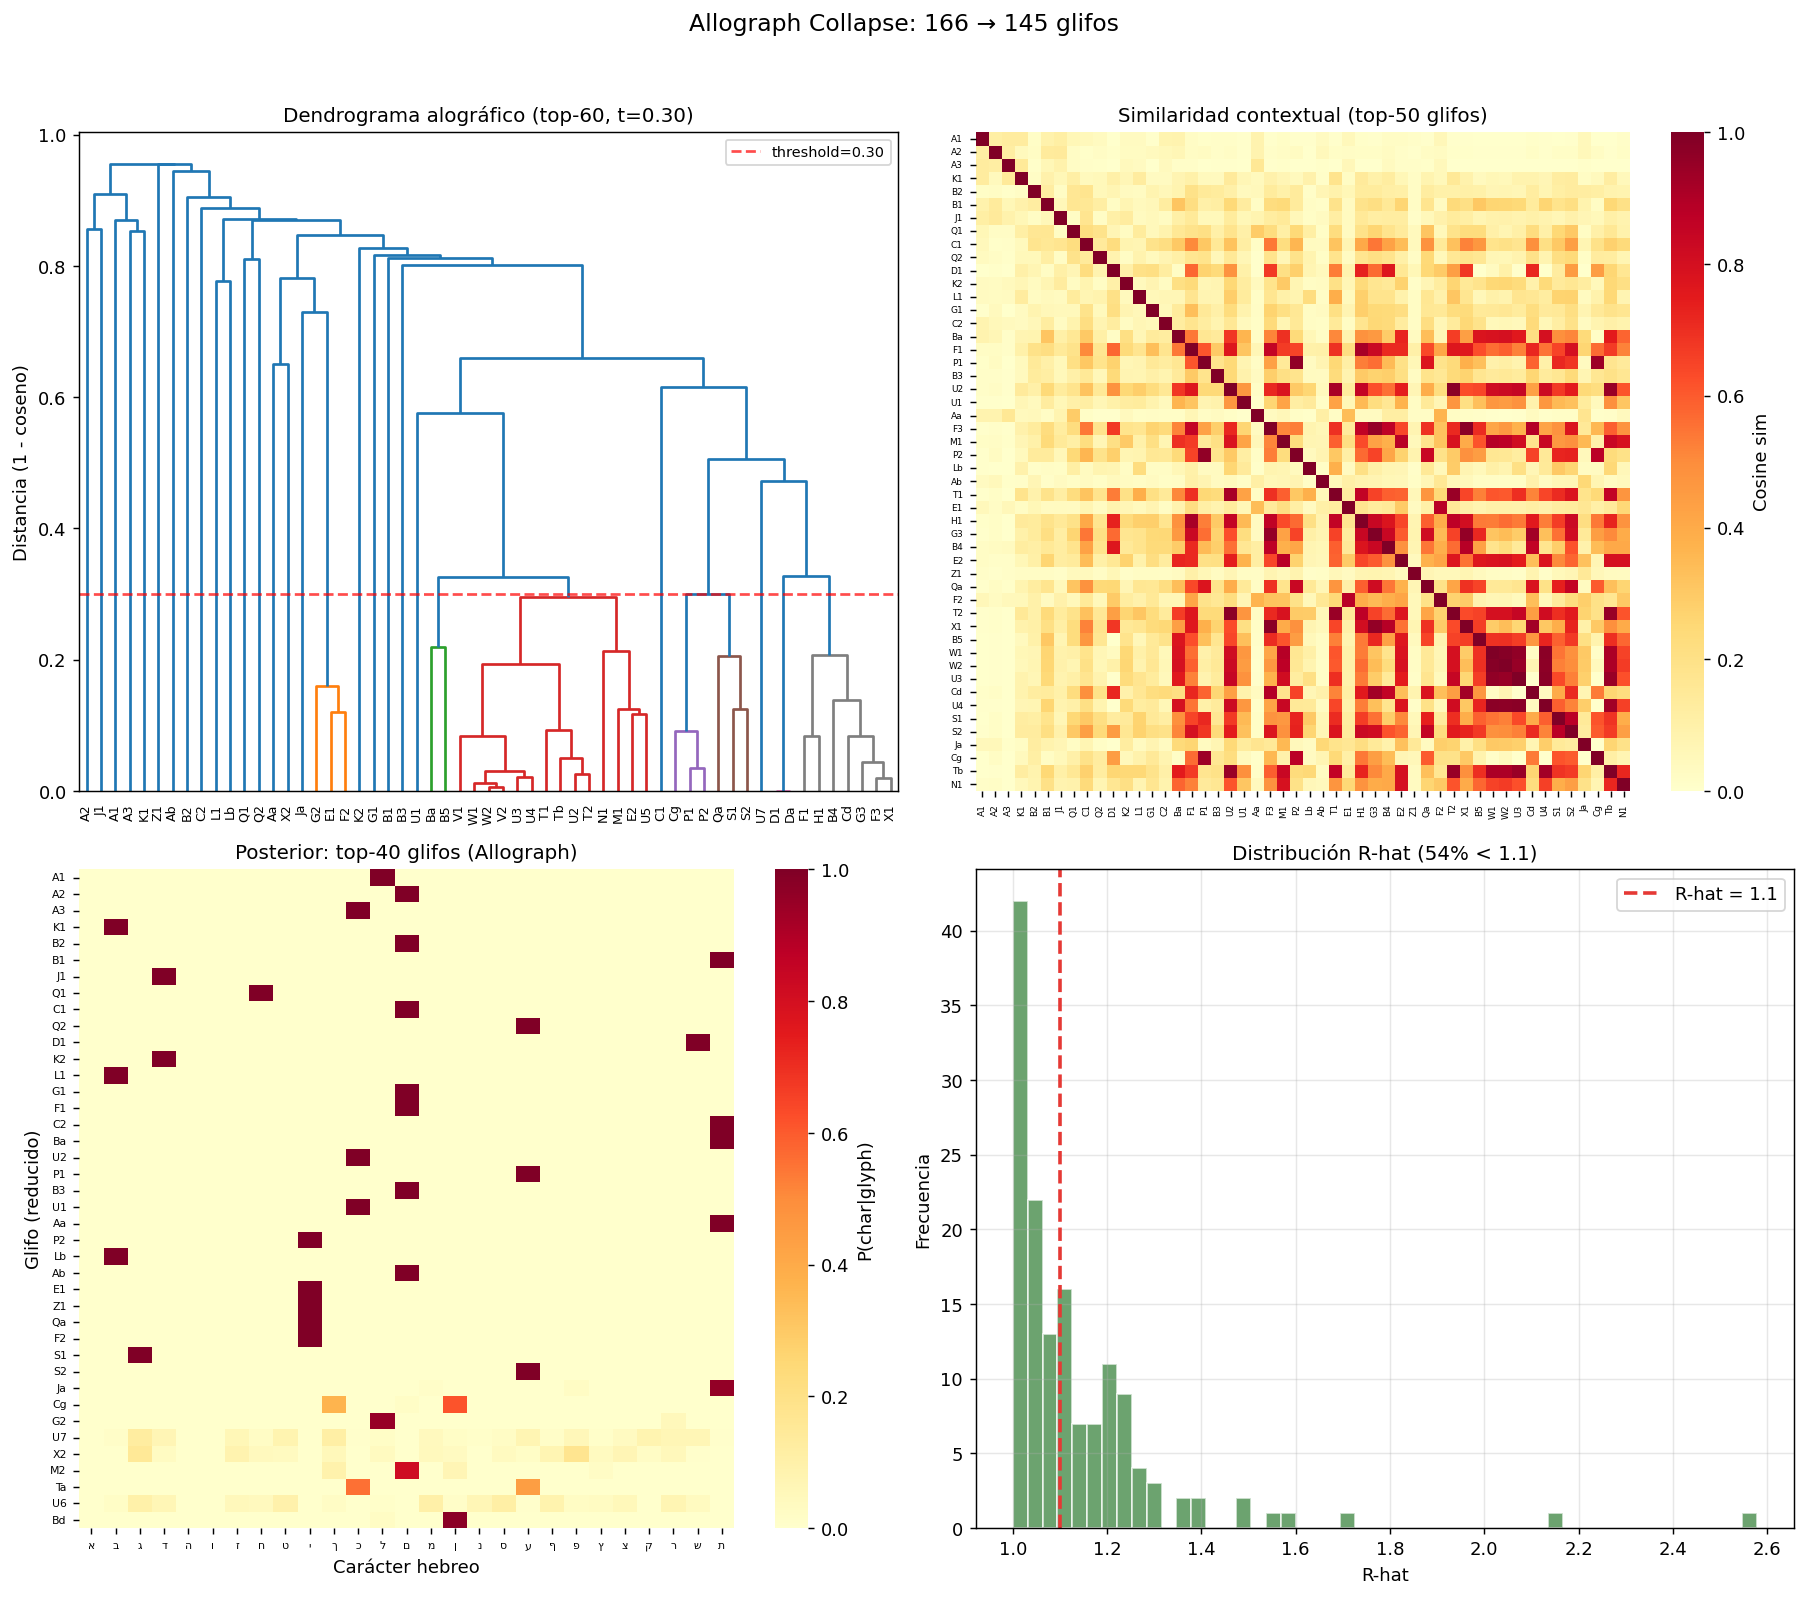

In [14]:
# ── Cell 14: Visualisations ──────────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Plot 1: Dendrogram colored by cluster (top-60)
ax = axes[0, 0]
dendrogram(Z_sub, labels=top60_labels, ax=ax, leaf_rotation=90, leaf_font_size=7,
           color_threshold=OPTIMAL_THRESHOLD)
ax.axhline(OPTIMAL_THRESHOLD, color='red', linestyle='--', alpha=0.7,
           label=f'threshold={OPTIMAL_THRESHOLD:.2f}')
ax.set_title(f'Allographic dendrogram (top-60, t={OPTIMAL_THRESHOLD:.2f})')
ax.set_ylabel('Distance (1 - cosine)')
ax.legend(fontsize=8)

# Plot 2: Contextual similarity heatmap (top-50)
ax = axes[0, 1]
top50_freq = sorted(freq_glyphs, key=lambda g: glyph_freq[g], reverse=True)[:50]
top50_idx = [freq_glyphs.index(g) for g in top50_freq]
top50_labels_h = [freq_glyphs[i] for i in top50_idx]
sim_sub50 = sim_context[np.ix_(top50_idx, top50_idx)]
sns.heatmap(sim_sub50, ax=ax, xticklabels=top50_labels_h, yticklabels=top50_labels_h,
            cmap='YlOrRd', vmin=0, vmax=1, cbar_kws={'label': 'Cosine sim'})
ax.set_title('Contextual similarity (top-50 glyphs)')
ax.tick_params(labelsize=5)

# Plot 3: Posterior heatmap (top-40 reduced glyphs)
ax = axes[1, 0]
top40_red = sorted(VOCAB_REDUCED, key=lambda g: glyph_freq_reduced[g], reverse=True)[:40]
heatmap_data = np.zeros((len(top40_red), len(target_chars_heb)))
for i, g in enumerate(top40_red):
    if g in posterior_allo:
        for c, prob in posterior_allo[g].items():
            if c in target_chars_heb:
                j = target_chars_heb.index(c)
                heatmap_data[i, j] = prob
sns.heatmap(heatmap_data, ax=ax, cmap='YlOrRd',
            xticklabels=target_chars_heb, yticklabels=top40_red,
            cbar_kws={'label': 'P(char|glyph)'})
ax.set_xlabel('Hebrew character')
ax.set_ylabel('Glyph (reduced)')
ax.set_title('Posterior: top-40 glyphs (Allograph)')
ax.tick_params(labelsize=6)

# Plot 4: R-hat distribution
ax = axes[1, 1]
rhat_finite = [v for v in rhat_vals if v < 5.0]
ax.hist(rhat_finite, bins=50, color='#2E7D32', alpha=0.7, edgecolor='white')
ax.axvline(1.1, color='#E53935', linestyle='--', linewidth=2, label='R-hat = 1.1')
ax.set_xlabel('R-hat')
ax.set_ylabel('Frequency')
ax.set_title(f'Distribution R-hat ({pct_converged:.0f}% < 1.1)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle(f'Allograph Collapse: {len(VOCAB)} → {len(VOCAB_REDUCED)} glyphs', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [15]:
# ── Cell 15: Export results → allograph_resultados.json ─────────

mapping_serializable = {g: c for g, c in mapping_allo.items()}

posterior_serializable = {}
for g, dist in posterior_allo.items():
    posterior_serializable[g] = {c: round(p, 4) for c, p in dist.items() if p > 0.01}

# Cluster info serializable
cluster_info_ser = {}
for rep, info in cluster_info.items():
    cluster_info_ser[rep] = {
        'members': info['members'],
        'freqs': info['freqs'],
        'roles': info['roles'],
        'positions': info['positions'],
    }

resultados = {
    'metadata': {
        'notebook': '17_allograph.ipynb',
        'model': 'allograph_collapse_neural_lstm',
        'language': 'hebrew',
        'description': 'Allograph collapse: positional variants merged, then neural LSTM decipherment',
    },
    'clustering': {
        'method': 'hierarchical_average_linkage',
        'sim_metric': 'cosine_on_transition_profiles',
        'optimal_threshold': round(float(OPTIMAL_THRESHOLD), 3),
        'vocab_original': len(VOCAB),
        'vocab_reduced': len(VOCAB_REDUCED),
        'reduction_pct': round(100 * (len(VOCAB) - len(VOCAB_REDUCED)) / len(VOCAB), 1),
        'n_clusters_multi': len(cluster_info),
        'cluster_map': {g: cluster_map[g] for g in VOCAB},
        'cluster_details': cluster_info_ser,
        'n_candidate_pairs': len(candidate_pairs),
        'n_complementary_pairs': sum(1 for p in candidate_pairs if p['complementary']),
    },
    'neural_lm': {
        'architecture': 'LSTM 2-layer, embed=32, hidden=192, dropout=0.2',
        'n_params': sum(p.numel() for p in neural_lm.parameters()),
        'train_epochs': len(train_losses),
        'best_val_loss': float(best_val_loss),
    },
    'em_results': [{
        'T': float(r['T']), 'seed': int(r['seed']),
        'score': round(float(r['score']), 4),
        'K_eff': int(r['K_eff']), 'grammar': round(float(r['grammar']), 3),
        'n_roots': int(r['n_roots']),
        'roots_list': sorted(r['roots']),
        'iter_converged': int(r['iter_converged']),
        'elapsed': round(float(r['elapsed']), 1),
    } for r in em_results],
    'best_candidate': {
        'T': float(BEST['T']),
        'seed': int(BEST['seed']),
        'score': round(float(BEST['score']), 4),
        'K_eff': int(BEST['K_eff']),
        'grammar': round(float(BEST['grammar']), 3),
        'n_roots_quick': int(BEST['n_roots']),
    },
    'mcmc_results': {
        'n_chains': N_CHAINS,
        'n_iter': N_ITER,
        'burn_in': BURN_IN,
        'best_score': round(float(global_best_score), 4),
        'K_eff': len(set(global_best.mapping.values())),
        'pct_converged_rhat': round(float(pct_converged), 1),
        'chain_accept_rates': [round(float(ch['accept_rate']), 3) for ch in mcmc_chains],
    },
    'validation_scorecard': {s['Test']: s['Verdict'] for s in scorecard},
    'validation_details': {
        'collapse_mean_z': round(float(mean_z), 3),
        'ngram_percentile': round(float(pct_ngram), 1),
        'ngram_jsd': round(float(real_jsd), 4),
        'roots_matched': int(len(roots_matched)),
        'roots_list': sorted(roots_matched),
        'enrichment': round(float(enrichment), 1),
        'cardinality_ratio': round(float(K_ratio), 3),
        'grammar_anchor_pct': round(float(pct_anchor), 3),
        'reduction_delta_ngram': round(float(delta_ngram), 1),
        'reduction_verdict': test6_verdict,
    },
    'scorecard_summary': f'{n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL',
    'mapping': mapping_serializable,
    'posterior_top': posterior_serializable,
    'rhat': {g: round(float(v), 4) for g, v in rhat_allo.items()
             if isinstance(v, (int, float, np.floating)) and not np.isnan(v)},
    'comparison_table': comparison_rows,
    'em_summary': {
        'n_seeds': N_SEEDS,
        'T_values': T_VALUES,
        'score_mean': round(float(np.mean([r['score'] for r in em_results])), 4),
        'score_std': round(float(np.std([r['score'] for r in em_results])), 4),
        'roots_mean': round(float(np.mean([r['n_roots'] for r in em_results])), 1),
        'roots_std': round(float(np.std([r['n_roots'] for r in em_results])), 1),
        'roots_max': int(max(r['n_roots'] for r in em_results)),
    },
}

class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, (np.integer,)): return int(obj)
        if isinstance(obj, (np.floating,)): return float(obj)
        if isinstance(obj, np.ndarray): return obj.tolist()
        if isinstance(obj, set): return sorted(obj)
        return super().default(obj)

with open('allograph_resultados.json', 'w') as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False, cls=NumpyEncoder)
print('Results exported to allograph_resultados.json')
print(f'Keys: {list(resultados.keys())}')

print(f'\n── Final summary ──')
print(f'Model: Allograph Collapse + Neural LSTM')
print(f'Vocabulary: {len(VOCAB)} → {len(VOCAB_REDUCED)} ({len(VOCAB)-len(VOCAB_REDUCED)} collapsed)')
print(f'Multi-glyph clusters: {len(cluster_info)}')
print(f'Best candidate: T={BEST["T"]}, seed={BEST["seed"]}')
print(f'Quick roots (pre-MCMC): {BEST["n_roots"]}')
print(f'Validated roots (post-MCMC): {len(roots_matched)}')
print(f'N-gram percentile: {pct_ngram:.1f}% (vs v2: {v2_ngram_pct:.1f}%, delta={delta_ngram:+.1f})')
print(f'Scorecard: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')
print(f'R-hat convergence: {pct_converged:.0f}%')

Results exported to allograph_resultados.json
Keys: ['metadata', 'clustering', 'neural_lm', 'em_results', 'best_candidate', 'mcmc_results', 'validation_scorecard', 'validation_details', 'scorecard_summary', 'mapping', 'posterior_top', 'rhat', 'comparison_table', 'em_summary']

── Final summary ──
Model: Allograph Collapse + Neural LSTM
Vocabulary: 166 → 145 (21 collapsed)
Multi-glyph clusters: 4
Best candidate: T=3.0, seed=0
Quick roots (pre-MCMC): 4
Validated roots (post-MCMC): 4
N-gram percentile: 23.0% (vs v2: 68.0%, delta=-45.0)
Scorecard: 4 PASS / 0 MARGINAL / 2 FAIL
R-hat convergencia: 54%
